<a href="https://colab.research.google.com/github/RaczNikoletta/Artificial-intelligence/blob/main/PE_SupervisedML/EMBER_2018_v2_osszesitett.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EMBER 2018 v2 – PE malware classification

## Projektáttekintés

A notebook célja a Windows Portable Executable (PE) fájlok statikus jellemzői alapján történő bináris osztályozás: **Benign (0)** vagy **Malware (1)**. A munkafolyamat bemutatja az adatbetöltést, az adatauditot, a feltáró elemzést, a feature-vizsgálatot, a modellválasztást és a végső kiértékelést.

A notebook az átdolgozott kísérleti folyamatot használja fő munkafolyamatként. Az eredeti próbálkozások tanulságait külön dokumentáljuk, de a korábbi, teszthalmazon végzett modell-összehasonlításokat nem használjuk fel végső teljesítményállításként.

## Kísérleti módszertan röviden

- A `-1` címkéjű, címkézetlen rekordok kimaradnak a felügyelt tanulásból.
- A mintavételezés osztályonként, a teljes Parquet-állomány feldolgozásával történik.
- A tanító mintákból külön train és validation halmaz készül; a teszthalmaz a végső értékelésre marad.
- A feature-választás és a döntési küszöb kiválasztása nem a teszthalmazon történik.

> Fontos: a mintavételező kód az eredeti osztályarányokat őrzi meg. A tényleges osztályarányokat mindig a futáskor kapott audit eredmények alapján kell közölni.


## A projekt második verziója – továbbfejlesztés és hibajavítás

Ez a notebook a projekt második változata. Az első próbálkozás során elkészült egy kezdeti adatelemzési és gépi tanulási folyamat, azonban a megvalósítás során több technikai és módszertani hiányosság is felmerült. A tapasztalatok alapján szükségessé vált a notebook szerkezetének átdolgozása, a hibás vagy hiányzó kódrészek javítása, valamint az elemzési folyamat következetesebbé tétele.

### Az első verzió során tapasztalt problémák

Az első változatban elsősorban az alábbi problémák merültek fel:

- **Nem megfelelően kezelt adatbetöltés:** a fájlok elérési útja túlságosan egy adott futtatási környezethez igazodott, ezért más környezetben (például Google Colabban vagy helyi gépen) problémák jelentkezhettek.
- **Hiányzó függvény- és változódefiníciók:** egyes kódrészletek olyan segédfüggvényekre és változókra hivatkoztak, amelyek nem voltak korábban definiálva. Ez futtatási hibákat eredményezett.
- **Hiányos adatszerkezet-ellenőrzés:** a tanító- és teszthalmaz oszlopainak összehasonlítása nem megfelelően előkészített változókkal történt, ami szintén megakadályozhatta a notebook futását.
- **Hibás hibaanalízis:** az utólagos kiértékelés során a helyesen és hibásan osztályozott minták indexeit a kód felhasználta, de azok előzetes meghatározása hiányzott.
- **A kódcellák közötti függőségek nem voltak kellően következetesek:** bizonyos cellák olyan korábbi futtatási állapotokra támaszkodtak, amelyek nem feltétlenül álltak rendelkezésre egy tiszta, újraindított környezetben.

Ezek a problémák rámutattak arra, hogy nem elegendő az egyes elemzési lépések külön-külön történő megvalósítása: fontos az is, hogy a teljes folyamat logikusan felépített, reprodukálható és egymás után végrehajtható legyen.

### A második verzióban elvégzett javítások

A második változatban a fenti problémák kezelésére az alábbi módosítások történtek:

- **Rugalmasabb adatbetöltés:** a notebook már nem kizárólag a Kaggle környezet könyvtárszerkezetére épít. Először megpróbálja az ott elérhető adatokat használni, egyébként pedig a `kagglehub` segítségével tölti le az adatkészletet.
- **Hiányzó segédfüggvények pótlása:** bekerült a fájlok keresését és a címkeeloszlás meghatározását végző függvények definíciója.
- **A változók definiálásának rendezése:** a tanító- és teszthalmaz oszlopainak ellenőrzéséhez szükséges változók már a felhasználásuk előtt létrejönnek.
- **A bemeneti adatok ellenőrzésének javítása:** a notebook az adatbetöltés során ellenőrzi, hogy a tanító- és teszthalmaz jellemzőoszlopai megfelelnek-e egymásnak.
- **A hibaanalízis javítása:** a helyesen és hibásan osztályozott minták indexei már közvetlenül az elemzés előtt meghatározásra kerülnek.
- **A korábbi futtatási eredmények eltávolítása:** a cellák korábbi kimenetei törlésre kerültek, így az új eredmények a jelenlegi kód tényleges futtatásából származhatnak.

### Összegzés

A második verzió célja nem csupán a korábbi futtatási hibák megszüntetése volt, hanem egy átláthatóbb, következetesebb és könnyebben reprodukálható elemzési folyamat kialakítása is. A fejlesztés során fontos tanulság volt, hogy a gépi tanulási projekt minőségét nem kizárólag a kiválasztott algoritmusok és az elért metrikák határozzák meg, hanem az adat-előkészítés, a kód szervezettsége, a cellák közötti függőségek és a kiértékelés megbízhatósága is.

A továbbiakban ezért a teljes folyamat egységes szerkezetben, az adatbetöltéstől az előfeldolgozáson és a modellépítésen át egészen a kiértékelésig kerül bemutatásra.

Különböző probálkozások elérhetőek: https://github.com/RaczNikoletta/Artificial-intelligence/tree/main/PE_SupervisedML


In [2]:
import os

import gc

from pathlib import Path

import numpy as np

import pandas as pd

import pyarrow.parquet as pq

import matplotlib.pyplot as plt

import seaborn as sns

import kagglehub

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

TRAIN_SAMPLE_SIZE = 40_000

TEST_SAMPLE_SIZE = 10_000

BATCH_SIZE = 5_000

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

print("Konfiguráció sikeresen betöltve.")

Konfiguráció sikeresen betöltve.


1.3. Adathalmaz letöltése és ellenőrzése

In [3]:
# Adatállomány megkeresése:
# 1. Kaggle Notebook esetén az Add Input könyvtárban keressük.
# 2. Google Colab / helyi környezet esetén KaggleHubbal letöltjük.

def find_dataset_file(root, filename):
    """Megkeresi a fájlt a megadott könyvtárban és annak alkönyvtáraiban."""
    root = Path(root)
    matches = list(root.rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Nem található a(z) {filename} fájl a következő helyen: {root}"
        )
    if len(matches) > 1:
        print(f"Figyelem: több példány található; az elsőt használom: {matches[0]}")
    return matches[0]


TRAIN_FILENAME = "train_ember_2018_v2_features.parquet"
TEST_FILENAME = "test_ember_2018_v2_features.parquet"

kaggle_input_root = Path("/kaggle/input")
train_matches = list(kaggle_input_root.rglob(TRAIN_FILENAME)) if kaggle_input_root.exists() else []
test_matches = list(kaggle_input_root.rglob(TEST_FILENAME)) if kaggle_input_root.exists() else []

if train_matches and test_matches:
    train_file = train_matches[0]
    test_file = test_matches[0]
    print("Kaggle Input könyvtárból használom az adatokat.")
else:
    print("Kaggle Input nem található; KaggleHub letöltés indul (Colab/local).")
    download_path = Path(
        kagglehub.dataset_download("dhoogla/ember-2018-v2-features")
    )
    train_file = find_dataset_file(download_path, TRAIN_FILENAME)
    test_file = find_dataset_file(download_path, TEST_FILENAME)

print("Train:", train_file)
print("Test:", test_file)

# A címke- és feature-oszlopok meghatározása a Parquet sémából.
train_columns = pq.ParquetFile(train_file).schema.names
test_columns = pq.ParquetFile(test_file).schema.names

LABEL_COL = next((col for col in train_columns if col.lower() == "label"), None)
if LABEL_COL is None:
    raise ValueError("A train állományban nem található Label oszlop.")

test_label_col = next((col for col in test_columns if col.lower() == "label"), None)
if test_label_col is None:
    raise ValueError("A test állományban nem található Label oszlop.")

FEATURE_COLS = [col for col in train_columns if col != LABEL_COL]
test_feature_cols = [col for col in test_columns if col != test_label_col]

if FEATURE_COLS != test_feature_cols:
    raise ValueError(
        "A train és test feature-oszlopai vagy azok sorrendje eltér. "
        "Ellenőrizd a két Parquet fájl sémáját."
    )

print(f"Feature oszlopok száma: {len(FEATURE_COLS)}")


Kaggle Input nem található; KaggleHub letöltés indul (Colab/local).


100%|██████████| 2.23G/2.23G [00:31<00:00, 76.4MB/s]

Extracting files...


Train: /root/.cache/kagglehub/datasets/dhoogla/ember-2018-v2-features/versions/2/train_ember_2018_v2_features.parquet
Test: /root/.cache/kagglehub/datasets/dhoogla/ember-2018-v2-features/versions/2/test_ember_2018_v2_features.parquet
Feature oszlopok száma: 2381


1.5. Reprezentatív mintavételezés
Ez lesz az első igazán fontos fejlesztés.

Ahelyett, hogy az első megfelelő batch-ekből válogatnánk, az egész Parquet állományt feldolgozzuk.

A módszer neve reservoir sampling, pontosabban itt véletlen prioritások alapján tartjuk meg a mintákat.

Az algoritmus minden rekordhoz véletlen prioritást rendel, és az egyes osztályokon belül a legkisebb prioritású rekordokat tartja meg.

Így az állomány sorrendje nem határozza meg, mely minták kerülnek a tanulóhalmazba.

Először készítünk egy függvényt, amely az eredeti osztályarányokat megtartva osztja el a mintavételi keretet:

In [4]:
def allocate_sample_counts(class_counts, sample_size):

    total = sum(class_counts.values())

    if total == 0:
        raise ValueError("Nincs címkézett adat.")

    sample_size = min(sample_size, total)

    quotas = {
        label: int(
            sample_size * count / total
        )
        for label, count in class_counts.items()
    }

    # A kerekítési különbség korrigálása
    remaining = sample_size - sum(quotas.values())

    order = sorted(
        class_counts,
        key=lambda label: (
            sample_size * class_counts[label] / total
            - quotas[label]
        ),
        reverse=True
    )

    for label in order:
        if remaining == 0:
            break

        if quotas[label] < class_counts[label]:
            quotas[label] += 1
            remaining -= 1

    return quotas

Mintavételezés

In [5]:
def count_dataset_labels(file_path):
    """Számolja meg a -1, 0 és 1 címkék előfordulását a teljes Parquet fájlban."""
    parquet_file = pq.ParquetFile(file_path)
    columns = parquet_file.schema.names
    label_col = next(
        (col for col in columns if col.lower() == "label"),
        None
    )
    if label_col is None:
        raise ValueError(f"Nem található Label oszlop: {file_path}")

    counts = {-1: 0, 0: 0, 1: 0}
    total_rows = 0

    for batch in parquet_file.iter_batches(
        batch_size=BATCH_SIZE,
        columns=[label_col]
    ):
        labels = batch.column(0).to_numpy(zero_copy_only=False)
        total_rows += len(labels)
        values, frequencies = np.unique(labels, return_counts=True)
        for value, frequency in zip(values, frequencies):
            value = int(value)
            counts[value] = counts.get(value, 0) + int(frequency)

    return counts, total_rows


def load_representative_sample(
    file_path,
    sample_size,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    parquet_file = pq.ParquetFile(file_path)

    columns = parquet_file.schema.names

    label_col = next(
        col for col in columns
        if col.lower() == "label"
    )

    feature_cols = [
        col for col in columns
        if col != label_col
    ]

    # Teljes állomány címkéinek megszámlálása
    class_counts, total_rows = count_dataset_labels(
        file_path
    )

    # A -1 címkét kizárjuk
    labeled_counts = {
        0: class_counts[0],
        1: class_counts[1]
    }

    quotas = allocate_sample_counts(
        labeled_counts,
        sample_size
    )

    print("Mintavételi keretek:", quotas)

    # Osztályonkénti tárolók
    reservoirs = {
        0: np.empty(
            (0, len(feature_cols)),
            dtype=np.float32
        ),
        1: np.empty(
            (0, len(feature_cols)),
            dtype=np.float32
        )
    }

    priorities = {
        0: np.empty(0),
        1: np.empty(0)
    }

    # A teljes Parquet állomány feldolgozása
    for batch in parquet_file.iter_batches(
        batch_size=BATCH_SIZE,
        columns=feature_cols + [label_col]
    ):

        df_batch = batch.to_pandas()

        y_batch = df_batch[label_col].to_numpy()

        X_batch = df_batch[feature_cols].to_numpy(
            dtype=np.float32,
            copy=False
        )

        for label in [0, 1]:

            quota = quotas[label]

            if quota == 0:
                continue

            mask = y_batch == label

            if not np.any(mask):
                continue

            X_class = X_batch[mask]

            new_priorities = rng.random(
                len(X_class)
            )

            # Korábbi és új minták egyesítése
            combined_X = np.concatenate([
                reservoirs[label],
                X_class
            ])

            combined_priorities = np.concatenate([
                priorities[label],
                new_priorities
            ])

            # A legkisebb prioritású minták megtartása
            if len(combined_priorities) > quota:

                keep = np.argpartition(
                    combined_priorities,
                    quota - 1
                )[:quota]

                reservoirs[label] = combined_X[keep]
                priorities[label] = combined_priorities[keep]

            else:

                reservoirs[label] = combined_X
                priorities[label] = combined_priorities

        del df_batch, X_batch, y_batch
        gc.collect()

    # Minták összefűzése
    X_sample = np.concatenate([
        reservoirs[0],
        reservoirs[1]
    ])

    y_sample = np.concatenate([
        np.zeros(len(reservoirs[0]), dtype=np.int8),
        np.ones(len(reservoirs[1]), dtype=np.int8)
    ])

    # Véletlenszerű sorrend
    shuffle_idx = rng.permutation(len(y_sample))

    X_sample = X_sample[shuffle_idx]
    y_sample = y_sample[shuffle_idx]

    print("\nMintavételezés kész.")
    print("Minták száma:", len(y_sample))
    print("Feature-ök száma:", X_sample.shape[1])
    print("Benign:", np.sum(y_sample == 0))
    print("Malware:", np.sum(y_sample == 1))

    return X_sample, y_sample, feature_cols

X_train_pool, y_train_pool, feature_names = (
    load_representative_sample(
        train_file,
        sample_size=TRAIN_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )
)

X_test, y_test, test_feature_names = (
    load_representative_sample(
        test_file,
        sample_size=TEST_SAMPLE_SIZE,
        random_state=RANDOM_STATE + 1
    )
)

assert feature_names == test_feature_names

print("\nVégleges alakzatok:")

print("Train pool:", X_train_pool.shape)

print("Test:", X_test.shape)

Mintavételi keretek: {0: 20002, 1: 19998}

Mintavételezés kész.
Minták száma: 40000
Feature-ök száma: 2381
Benign: 20002
Malware: 19998
Mintavételi keretek: {0: 5000, 1: 5000}

Mintavételezés kész.
Minták száma: 10000
Feature-ök száma: 2381
Benign: 5000
Malware: 5000

Végleges alakzatok:
Train pool: (40000, 2381)
Test: (10000, 2381)


A természetes osztályarányok megőrzése azért előnyös, mert később valósághűbb tesztelést tesz lehetővé. Ha az osztályok aránya nagyon eltérő, azt a modell tanításakor külön kezelhetjük.

1.7. Train, validation és test szétválasztása
A korábbi notebookodban közvetlenül a train és test készletekkel dolgoztál.

Most bevezetünk egy harmadik halmazt is.
- Train: a modell megtanulja a mintázatokat.
- Validation: ezen választjuk ki a legjobb modellt és paramétereket.
- Test: csak a végső értékelésre használjuk.
A 40 000 tanító mintából 80–20%-os felosztást készítünk.

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_pool
)

del X_train_pool, y_train_pool

gc.collect()

print("Train:", X_train.shape, y_train.shape)

print("Validation:", X_val.shape, y_val.shape)

print("Test:", X_test.shape, y_test.shape)

Train: (32000, 2381) (32000,)
Validation: (8000, 2381) (8000,)
Test: (10000, 2381) (10000,)


1.8. Dataset audit
Most ellenőrizzük, hogy milyen minőségű adatokkal fogunk dolgozni.

In [7]:
def dataset_audit(name, X, y):

    class_counts = pd.Series(y).value_counts().reindex(
        [0, 1],
        fill_value=0
    )

    print(f"\n{'='*45}")
    print(f"DATASET AUDIT: {name}")
    print(f"{'='*45}")

    print("Minták száma:", X.shape[0])
    print("Feature-ök száma:", X.shape[1])
    print("Adattípus:", X.dtype)

    print("\nOsztályeloszlás:")
    print(class_counts.rename({
        0: "Benign",
        1: "Malware"
    }))

    print("\nOsztályarány (%):")
    print(
        (class_counts / len(y) * 100).round(2)
    )

    nan_count = np.isnan(X).sum()
    inf_count = np.isinf(X).sum()

    print("\nAdatminőség:")
    print("NaN értékek:", nan_count)
    print("Végtelen értékek:", inf_count)

    print(
        "Olyan feature-ök, amelyekben van NaN:",
        np.isnan(X).any(axis=0).sum()
    )

    print(
        "Olyan feature-ök, amelyekben van Inf:",
        np.isinf(X).any(axis=0).sum()
    )

    print("Címkék:", np.unique(y))

    return {
        "dataset": name,
        "samples": X.shape[0],
        "features": X.shape[1],
        "benign": int(class_counts[0]),
        "malware": int(class_counts[1]),
        "nan": int(nan_count),
        "inf": int(inf_count)
    }

audit_results = []

audit_results.append(
    dataset_audit("Train", X_train, y_train)
)

audit_results.append(
    dataset_audit("Validation", X_val, y_val)
)

audit_results.append(
    dataset_audit("Test", X_test, y_test)
)

audit_df = pd.DataFrame(audit_results)

display(audit_df)


DATASET AUDIT: Train
Minták száma: 32000
Feature-ök száma: 2381
Adattípus: float32

Osztályeloszlás:
Benign     16002
Malware    15998
Name: count, dtype: int64

Osztályarány (%):
0    50.01
1    49.99
Name: count, dtype: float64

Adatminőség:
NaN értékek: 0
Végtelen értékek: 0
Olyan feature-ök, amelyekben van NaN: 0
Olyan feature-ök, amelyekben van Inf: 0
Címkék: [0 1]

DATASET AUDIT: Validation
Minták száma: 8000
Feature-ök száma: 2381
Adattípus: float32

Osztályeloszlás:
Benign     4000
Malware    4000
Name: count, dtype: int64

Osztályarány (%):
0    50.0
1    50.0
Name: count, dtype: float64

Adatminőség:
NaN értékek: 0
Végtelen értékek: 0
Olyan feature-ök, amelyekben van NaN: 0
Olyan feature-ök, amelyekben van Inf: 0
Címkék: [0 1]

DATASET AUDIT: Test
Minták száma: 10000
Feature-ök száma: 2381
Adattípus: float32

Osztályeloszlás:
Benign     5000
Malware    5000
Name: count, dtype: int64

Osztályarány (%):
0    50.0
1    50.0
Name: count, dtype: float64

Adatminőség:
NaN értékek:

,dataset,samples,features,benign,malware,nan,inf
0,Train,32000,2381,16002,15998,0,0
1,Validation,8000,2381,4000,4000,0,0
2,Test,10000,2381,5000,5000,0,0


1.9. Az osztályeloszlás vizualizációja

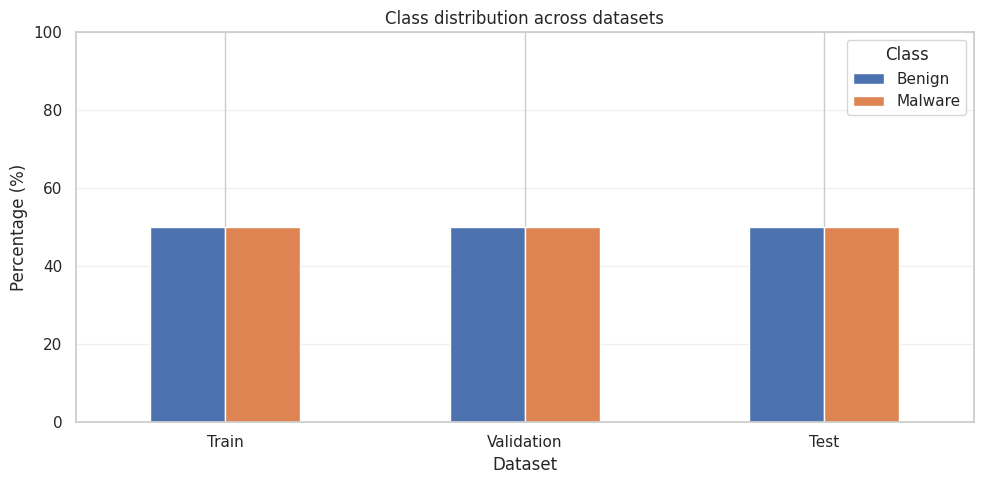

In [8]:
distributions = {}

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:

    counts = pd.Series(y).value_counts(normalize=True)

    distributions[name] = [
        counts.get(0, 0) * 100,
        counts.get(1, 0) * 100
    ]

distribution_df = pd.DataFrame(
    distributions,
    index=["Benign", "Malware"]
).T

ax = distribution_df.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Class distribution across datasets")

plt.ylabel("Percentage (%)")

plt.xlabel("Dataset")

plt.legend(title="Class")

plt.ylim(0, 100)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

In [9]:
FEATURE_GROUPS = {
    "Byte histogram": {
        "start": 0,
        "end": 256,
        "description": "Byte frequency distribution"
    },
    "Byte entropy": {
        "start": 256,
        "end": 512,
        "description": "Byte and local entropy distribution"
    },
    "Strings": {
        "start": 512,
        "end": 616,
        "description": "String statistics"
    },
    "General": {
        "start": 616,
        "end": 626,
        "description": "General PE file information"
    },
    "Header": {
        "start": 626,
        "end": 688,
        "description": "PE and COFF header information"
    },
    "Section": {
        "start": 688,
        "end": 943,
        "description": "PE section information"
    },
    "Imports": {
        "start": 943,
        "end": 2223,
        "description": "Imported libraries and functions"
    },
    "Exports": {
        "start": 2223,
        "end": 2351,
        "description": "Exported functions"
    },
    "Data directories": {
        "start": 2351,
        "end": 2381,
        "description": "PE data directory information"
    }
}

expected_feature_names = [f"F{i}" for i in range(1, 2382)]

if feature_names != expected_feature_names:
    raise ValueError(
        "A feature oszlopok neve vagy sorrendje eltér a várttól. "
        "Ne alkalmazd automatikusan a csoportosítást!"
    )

group_mapping_df = pd.DataFrame([
    {
        "group": name,
        "start_column": f"F{info['start'] + 1}",
        "end_column": f"F{info['end']}",
        "n_features": info["end"] - info["start"],
        "description": info["description"]
    }
    for name, info in FEATURE_GROUPS.items()
])

display(group_mapping_df)

assert sum(
    info["end"] - info["start"]
    for info in FEATURE_GROUPS.values()
) == X_train.shape[1]

,group,start_column,end_column,n_features,description
0,Byte histogram,F1,F256,256,Byte frequency distribution
1,Byte entropy,F257,F512,256,Byte and local entropy distribution
2,Strings,F513,F616,104,String statistics
3,General,F617,F626,10,General PE file information
4,Header,F627,F688,62,PE and COFF header information
5,Section,F689,F943,255,PE section information
6,Imports,F944,F2223,1280,Imported libraries and functions
7,Exports,F2224,F2351,128,Exported functions
8,Data directories,F2352,F2381,30,PE data directory information


2.3. Mennyire ritkák a feature-értékek?
A malware-detekcióban különösen fontos, hogy egy feature milyen gyakran vesz fel nulla értéket. Például egy adott importált függvény sok fájlból hiányozhat, míg egy általános PE-jellemző szinte minden fájlnál jelen lehet.

A következő cella csoportonként megvizsgálja:
- a nullától különböző értékek arányát;
- a feature-értékek átlagos szórását;
- a malware és benign minták közötti eltérést.

In [10]:
def calculate_group_statistics(X, y, groups):
    results = []

    for group_name, info in groups.items():
        start = info["start"]
        end = info["end"]

        X_group = X[:, start:end]

        benign = X_group[y == 0]
        malware = X_group[y == 1]

        # Nem nulla értékek aránya
        nonzero_percentage = np.mean(X_group != 0) * 100

        # Feature-önkénti szórás
        feature_std = np.std(X_group, axis=0)

        # Feature-önkénti Cohen-féle d
        mean_benign = np.mean(benign, axis=0)
        mean_malware = np.mean(malware, axis=0)

        std_benign = np.var(benign, axis=0)
        std_malware = np.var(malware, axis=0)

        pooled_std = np.sqrt(
            (std_benign + std_malware) / 2
        )

        effect_size = np.divide(
            mean_malware - mean_benign,
            pooled_std,
            out=np.zeros_like(mean_benign),
            where=pooled_std > 1e-12
        )

        results.append({
            "feature_group": group_name,
            "n_features": end - start,
            "nonzero_percentage": nonzero_percentage,
            "median_feature_std": np.median(feature_std),
            "median_abs_effect_size": np.median(
                np.abs(effect_size)
            ),
            "mean_abs_effect_size": np.mean(
                np.abs(effect_size)
            )
        })

    return pd.DataFrame(results)

group_statistics = calculate_group_statistics(
    X_train,
    y_train,
    FEATURE_GROUPS
)

display(
    group_statistics.sort_values(
        "median_abs_effect_size",
        ascending=False
    ).round(4)
)

,feature_group,n_features,nonzero_percentage,median_feature_std,median_abs_effect_size,mean_abs_effect_size
0,Byte histogram,256,98.3558,2.500000e-03,0.2664,0.2605
2,Strings,104,93.3508,8.200000e-03,0.2480,0.2509
3,General,10,53.0084,1.064622e+02,0.1349,0.2209
1,Byte entropy,256,66.0158,3.900000e-03,0.0612,0.1312
6,Imports,1280,7.1821,2.446000e-01,0.0574,0.0779
4,Header,62,23.8957,7.400000e-02,0.0442,0.1961
5,Section,255,8.0765,5.692000e-01,0.0197,0.0553
8,Data directories,30,32.5209,1.722195e+07,0.0173,0.0207
7,Exports,128,2.5763,4.857000e-01,0.0128,0.0157


- nonzero_percentage: mennyire ritkák a nem nulla értékek az adott csoportban.
- median_feature_std: mennyire változatosak az értékek.
- median_abs_effect_size: mekkora az átlagok közötti standardizált eltérés tipikus mértéke a két osztály között.
- mean_abs_effect_size: az előző mutató átlaga; néhány nagyon eltérő feature jobban befolyásolhatja.
A Cohen-féle d itt leíró mutató, nem bizonyítja önmagában, hogy egy feature okozza a malware-jelleget vagy jól fog működni egy modellben.

2.4. Az eredmények vizualizálása

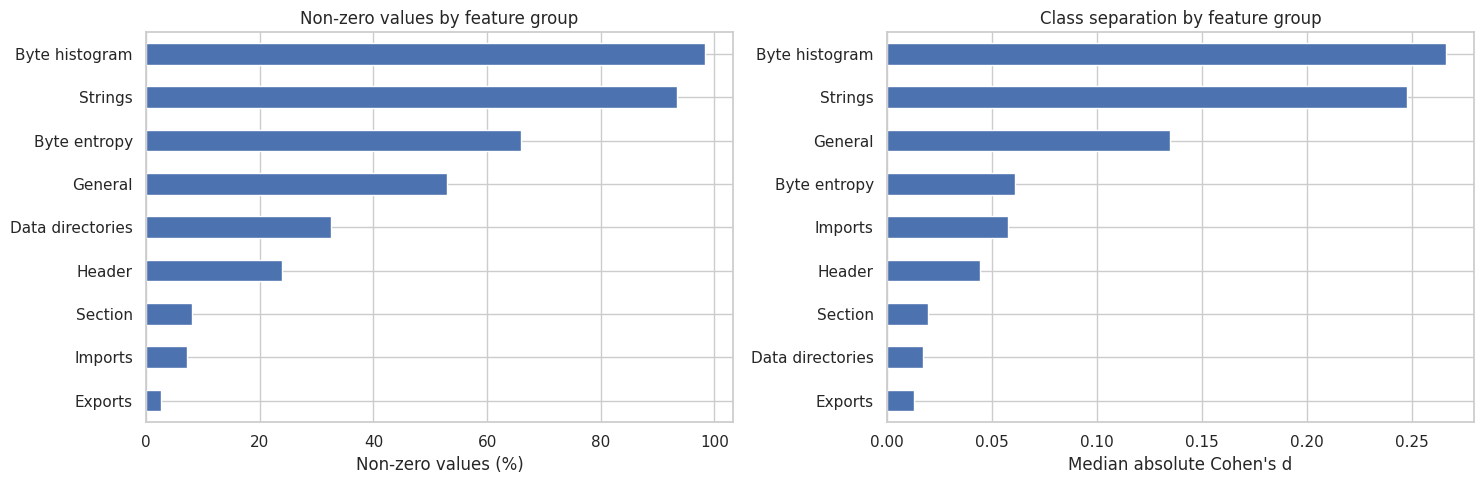

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

group_statistics.sort_values(
    "nonzero_percentage"
).plot(
    x="feature_group",
    y="nonzero_percentage",
    kind="barh",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Non-zero values by feature group")

axes[0].set_xlabel("Non-zero values (%)")

axes[0].set_ylabel("")

group_statistics.sort_values(
    "median_abs_effect_size"
).plot(
    x="feature_group",
    y="median_abs_effect_size",
    kind="barh",
    ax=axes[1],
    legend=False
)

axes[1].set_title("Class separation by feature group")

axes[1].set_xlabel("Median absolute Cohen's d")

axes[1].set_ylabel("")

plt.tight_layout()

plt.show()

2.5. Mely feature-ök különböztetik meg leginkább a két osztályt?
Most már csoportszinten látjuk a különbségeket. A következő cellával egyedi feature-öket is rangsorolunk.

In [12]:
benign_X = X_train[y_train == 0]

malware_X = X_train[y_train == 1]

benign_mean = np.mean(benign_X, axis=0)

malware_mean = np.mean(malware_X, axis=0)

benign_var = np.var(benign_X, axis=0)

malware_var = np.var(malware_X, axis=0)

pooled_std = np.sqrt((benign_var + malware_var) / 2)

cohens_d = np.divide(
    malware_mean - benign_mean,
    pooled_std,
    out=np.zeros_like(benign_mean),
    where=pooled_std > 1e-12
)

def get_feature_group(feature_index):
    for group_name, info in FEATURE_GROUPS.items():
        if info["start"] <= feature_index < info["end"]:
            return group_name
    return "Unknown"

feature_effects = pd.DataFrame({
    "feature": feature_names,
    "feature_index": np.arange(len(feature_names)),
    "benign_mean": benign_mean,
    "malware_mean": malware_mean,
    "cohens_d": cohens_d,
    "abs_cohens_d": np.abs(cohens_d)
})

feature_effects["feature_group"] = feature_effects[
    "feature_index"
].apply(get_feature_group)

top_features = feature_effects.sort_values(
    "abs_cohens_d",
    ascending=False
).head(20)

display(top_features.round(4))

,feature,feature_index,benign_mean,malware_mean,cohens_d,abs_cohens_d,feature_group
637,F638,637,-0.4569,-0.0615,1.0112,1.0112,Header
655,F656,655,-0.6952,-0.9695,-0.7874,0.7874,Header
1060,F1061,1060,0.5331,0.8851,0.7590,0.7590,Imports
658,F659,658,-0.7566,-0.3225,0.7420,0.7420,Header
114,F115,114,0.0084,0.0047,-0.6901,0.6901,Byte histogram
654,F655,654,0.2701,0.0293,-0.6896,0.6896,Header
618,F619,618,0.5497,0.2397,-0.6686,0.6686,General
116,F117,116,0.0122,0.0078,-0.6620,0.6620,Byte histogram
111,F112,111,0.0087,0.0045,-0.6569,0.6569,Byte histogram
496,F497,496,0.0143,0.0324,0.6302,0.6302,Byte entropy


## 3. Korábbi kísérleti megközelítés és módszertani tanulságok

Az eredeti notebookban először az első 50 000 címkézett rekord összegyűjtése történt. Ez a mintavétel az adathalmaz sorrendje miatt csak benign mintákat eredményezett, ezért alkalmatlan volt a kétosztályos tanulásra. A következő változat már mindkét osztályból választott, de csak addig olvasta a fájlt, amíg a szükséges osztályonkénti elemszám össze nem gyűlt; ez nem biztosította a teljes állományból történő véletlen mintavételt.

Az eredeti modellkísérletek Random Forest és XGBoost osztályozókat, standardizálást, valamint 95%-os magyarázott varianciára beállított PCA-t vizsgáltak. Ezek hasznos kezdeti próbálkozások voltak, de a teszthalmazt több modell- és küszöbválasztási döntéshez is felhasználták. Emiatt az ott kapott teszteredmények optimista, a tesztkészletre hangolódott becslések lehetnek, és nem hasonlíthatók közvetlenül a mostani, elkülönített tesztértékeléshez.

A PCA 2D-ábrája ebben a notebookban feltáró vizualizációként megmarad. A PCA nem része a végleges ExtraTrees-modell pipeline-jának; a kétkomponensű vetület a teljes variancia kis részét mutatja, ezért az osztályok átfedése nem bizonyítja, hogy a teljes 2381 dimenziós térben ne lennének elkülöníthetők.

**Miért változott a módszertan?** A teljes állományt feldolgozó, osztályonkénti mintavételezés csökkenti a fájlsorrendből eredő torzítást; a külön validációs halmaz pedig lehetővé teszi a modell- és küszöbválasztást úgy, hogy a tesztkészlet a végső mérésre maradjon.


A legfontosabb megfigyelések
1. A Byte histogram és a Strings csoport sok általános információt hordoz.
- Byte histogram: a feature-értékek 98,36%-a nem nulla.
- Strings: 93,35%.
- Mindkét csoportnál viszonylag magas a medián effektusméret.
Ez arra utal, hogy ezekben a csoportokban sok feature változik a fájlok között, és az osztályok közötti különbség sem csak néhány kiugró értékből ered.

2. A Header csoportban néhány kiemelkedő feature található.

A medián abszolút Cohen-d mindössze 0,0442, de a húsz legerősebb feature között több Header-jellemző is szerepel.

Ez azt jelenti, hogy a csoporton belül valószínűleg néhány feature sokkal informatívabb, mint a többi.

3. Az Imports csoport különösen érdekes.

1280 feature-ből áll, de a nem nulla értékek aránya mindössze 7,18%.

Ez nem feltétlenül hátrány: az importált függvények és könyvtárak jelenléte vagy hiánya sok esetben hasznos információt hordozhat a fájl működéséről.

4. Az Exports csoport egyelőre kevésbé ígéretes.

Mindössze 2,58%-os nem nulla arány és alacsony medián effektusméret jellemzi. Ettől még kombinációban hasznos lehet.
Egy fontos módszertani megjegyzés
A median_feature_std értékeket ne hasonlítsuk közvetlenül a csoportok között. A különböző feature-csoportok eltérő skálán és eloszlással rendelkezhetnek.

A Cohen-d viszont standardizált mutató, ezért alkalmasabb az osztályok közötti eltérések összehasonlítására.

A táblázat alapján még nem tudjuk, hogy melyik csoportból lehet a legjobb malware-detektort építeni. Ehhez modellekkel is meg kell vizsgálnunk őket.

PCA alapú dimenziócsökkentés és adateloszlás vizualizációja

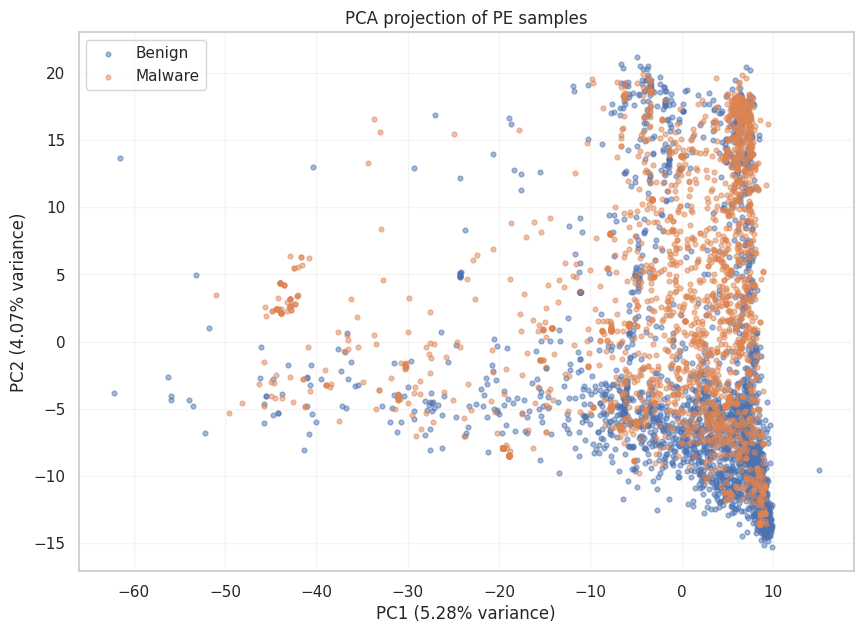

Explained variance: 9.34%


In [13]:
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import numpy as np

rng = np.random.default_rng(RANDOM_STATE)

pca_sample_size = min(5000, len(y_train))

pca_indices = rng.choice(
    len(y_train),
    size=pca_sample_size,
    replace=False
)

X_pca_sample = X_train[pca_indices]

y_pca_sample = y_train[pca_indices]

scaler_pca = StandardScaler()

X_scaled = scaler_pca.fit_transform(X_pca_sample)

pca = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(10, 7))

for label, name in [(0, "Benign"), (1, "Malware")]:
    mask = y_pca_sample == label

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=name,
        alpha=0.5,
        s=12
    )

plt.xlabel(
    f"PC1 ({explained_variance[0]*100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance[1]*100:.2f}% variance)"
)

plt.title("PCA projection of PE samples")

plt.legend()

plt.grid(alpha=0.2)

plt.show()

print(
    f"Explained variance: "
    f"{explained_variance.sum()*100:.2f}%"
)

### PCA alapú dimenziócsökkentés és vizualizáció

A 2381 dimenziós PE feature-készlet szerkezetének vizsgálatához Principal Component Analysis (PCA) segítségével két dimenzióra vetítettük a mintákat. Az elemzés során a tanítóadatokból véletlenszerűen kiválasztott 5000 mintát használtunk, amelyeken a PCA alkalmazása előtt standardizáltuk a jellemzőket.

Az első főkomponens (PC1) az adatok varianciájának 5,28%-át, a második főkomponens (PC2) pedig 4,07%-át magyarázza. A két komponens együttesen 9,34%-os magyarázott varianciát biztosít.

A vizualizáció alapján a benign és malware minták között jelentős átfedés figyelhető meg. A két osztály nem különül el egyértelműen a kétdimenziós vetületben, és a minták egy része szélsőséges értékeket mutat a főkomponensek mentén.

Fontos kiemelni, hogy a két komponens által megőrzött variancia viszonylag alacsony, ezért az ábra az eredeti adatok információtartalmának csak egy részét jeleníti meg. A vizualizációból nem következik, hogy a két osztály az eredeti, magas dimenziós feature-térben sem különíthető el.

A PCA-t ebben a projektben kizárólag feltáró adatelemzési és vizualizációs célra alkalmaztuk. A végső ExtraTrees modell az eredeti feature-készletből kiválasztott 250 jellemzőt használta, PCA-transzformáció nélkül.

Feature group ablation study
Most azt fogjuk megvizsgálni, hogy az egyes feature-csoportok önmagukban mennyire alkalmasak malware-detektálásra.

Például:
- Milyen eredményt érünk el kizárólag a Header adatokkal?
- Mennyire jól működik a modell csak az Imports adatokkal?
- Melyik csoport adja a legjobb eredményt?
- Mennyit javít az eredmény, ha minden csoportot együtt használunk?
Ez az egyik legfontosabb vizsgálat lesz a projektben.
2.1. Modell és metrikák
Most egy Extra Trees osztályozót használunk. Ez egy faalapú ensemble algoritmus, amelyhez nem szükséges standardizálni a feature-öket.

A modelleket kizárólag a train halmazon tanítjuk, és a validation halmazon értékeljük.

In [14]:
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score
)

def evaluate_feature_group(
    X_train,
    y_train,
    X_val,
    y_val,
    feature_indices,
    group_name
):
    X_train_group = X_train[:, feature_indices]
    X_val_group = X_val[:, feature_indices]

    model = ExtraTreesClassifier(
        n_estimators=150,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_group, y_train)

    y_pred = model.predict(X_val_group)
    y_proba = model.predict_proba(X_val_group)[:, 1]

    return {
        "feature_group": group_name,
        "n_features": len(feature_indices),
        "roc_auc": roc_auc_score(y_val, y_proba),
        "pr_auc": average_precision_score(y_val, y_proba),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, y_pred
        ),
        "f1": f1_score(y_val, y_pred)
    }

Minden feature-csoport külön vizsgálata

In [15]:
group_results = []

for group_name, info in FEATURE_GROUPS.items():

    feature_indices = np.arange(
        info["start"],
        info["end"]
    )

    print(f"Training model: {group_name}")

    result = evaluate_feature_group(
        X_train,
        y_train,
        X_val,
        y_val,
        feature_indices,
        group_name
    )

    group_results.append(result)

group_results_df = pd.DataFrame(group_results)

display(
    group_results_df.sort_values(
        "roc_auc",
        ascending=False
    ).round(4)
)

Training model: Byte histogram
Training model: Byte entropy
Training model: Strings
Training model: General
Training model: Header
Training model: Section
Training model: Imports
Training model: Exports
Training model: Data directories


,feature_group,n_features,roc_auc,pr_auc,balanced_accuracy,f1
2,Strings,104,0.9675,0.9700,0.8962,0.8962
0,Byte histogram,256,0.9662,0.9691,0.8924,0.8914
1,Byte entropy,256,0.9636,0.9671,0.8932,0.8924
8,Data directories,30,0.9475,0.9512,0.8631,0.8657
6,Imports,1280,0.9452,0.9502,0.8679,0.8628
5,Section,255,0.9198,0.9252,0.8385,0.8355
4,Header,62,0.8999,0.8982,0.7864,0.8139
3,General,10,0.8679,0.8738,0.7606,0.7646
7,Exports,128,0.5959,0.5679,0.5756,0.6933


Összes feature együttes használata
Most megnézzük, hogy az összes feature együttesen milyen eredményt ad.

,feature_group,n_features,roc_auc,pr_auc,balanced_accuracy,f1
0,All features,2381,0.9864,0.9876,0.938,0.9376


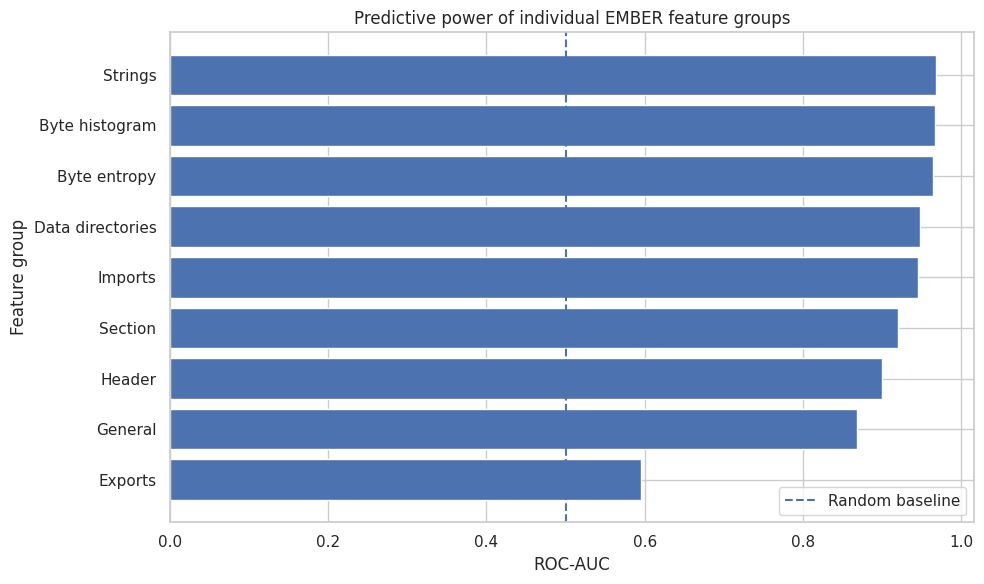

In [16]:
all_feature_indices = np.arange(X_train.shape[1])

all_features_result = evaluate_feature_group(
    X_train,
    y_train,
    X_val,
    y_val,
    all_feature_indices,
    "All features"
)

all_features_df = pd.DataFrame([all_features_result])

display(all_features_df.round(4))

plot_df = group_results_df.sort_values(
    "roc_auc",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["feature_group"],
    plot_df["roc_auc"]
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("ROC-AUC")

plt.ylabel("Feature group")

plt.title("Predictive power of individual EMBER feature groups")

plt.legend()

plt.tight_layout()

plt.show()

Mit jelentenek ezek malware-elemzési szempontból?
- Strings: a fájlokban található karakterláncok és szöveges mintázatok erősen különböztetik meg a két osztályt. Ez összhangban van azzal, hogy a malware-ekben gyakran találhatók jellegzetes API-nevek, fájlnevek, URL-ek vagy egyéb szöveges indikátorok.
- Byte histogram: a bájtértékek gyakorisági eloszlása eltérhet a benign és malware fájlok között. Ez a fájlok bináris szerkezetéből származó statisztikai mintázatokat ragadja meg.
- Byte entropy: a bájtok entrópiája a fájl különböző részeinek információs változatosságáról ad képet. Tömörített vagy titkosított tartalom például eltérő mintázatot eredményezhet.
- Imports: az importált függvények és könyvtárak alapján következtetni lehet arra, hogy egy program milyen műveleteket képes végrehajtani.
- Exports: ebben a mintában az export feature-csoport önmagában gyenge. Ez nem jelenti azt, hogy az exportok soha nem hasznosak, csak azt, hogy a mostani mintán és modellel kevés önálló elkülönítő információt adnak.
Fontos: ezek lehetséges szakmai magyarázatok, nem bizonyítják, hogy egy adott feature-csoport konkrét malware-viselkedést azonosít.
2. Egy érdekes ellentmondás az eredményekben
Korábban a Cohen-féle hatásméret alapján a Header csoportban találtál több kiemelkedő egyedi feature-t. Most viszont a Header-csoport önálló ROC-AUC értéke csak 0.8999.

Ez nem ellentmondás: az egyedi feature-ök közötti különbség nem feltétlenül jelenti azt, hogy a teljes csoport együttesen is olyan jól osztályoz. A Strings esetében viszont sok feature együtt nagyon erős prediktív mintázatot alkothat.

A legfontosabb megfigyelés, hogy a feature-csoportok önálló teljesítménye és a teljes modell teljesítménye között jelentős különbség van:
- A Strings önmagában 0.9675 ROC-AUC-t ér el, a teljes modell viszont 0.9864-et.
- A Byte histogram és Byte entropy is közel 0.97-es eredményt ad önmagában.
- A teljes modell 0.9864-es eredménye arra utal, hogy a különböző feature-csoportok kombinációja további hasznos információt hordozhat.
Viszont még nem tudjuk, hogy melyik csoport mennyivel járul hozzá ehhez a javuláshoz. Ezt fogjuk most megvizsgálni.

Leave-one-feature-group-out
Most minden feature-csoportot egyenként kihagyunk, és újratanítjuk a modellt. Így mérhető, hogy az adott csoport elhagyásával mennyit romlik vagy javul a teljesítmény.

In [17]:
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score
)

baseline_roc_auc = 0.9864

baseline_pr_auc = 0.9876

ablation_results = []

for group_name, info in FEATURE_GROUPS.items():
    start = info["start"]
    end = info["end"]

    # Keep every feature except the current group
    keep_indices = list(range(0, start)) + list(range(end, X_train.shape[1]))

    X_train_reduced = X_train[:, keep_indices]
    X_val_reduced = X_val[:, keep_indices]

    model = ExtraTreesClassifier(
        n_estimators=150,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_reduced, y_train)

    y_proba = model.predict_proba(X_val_reduced)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    roc_auc = roc_auc_score(y_val, y_proba)
    pr_auc = average_precision_score(y_val, y_proba)
    balanced_acc = balanced_accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    ablation_results.append({
        "excluded_group": group_name,
        "remaining_features": len(keep_indices),
        "roc_auc": roc_auc,
        "roc_auc_drop": baseline_roc_auc - roc_auc,
        "pr_auc": pr_auc,
        "pr_auc_drop": baseline_pr_auc - pr_auc,
        "balanced_accuracy": balanced_acc,
        "f1": f1
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df = ablation_df.sort_values(
    "roc_auc_drop", ascending=False
).reset_index(drop=True)

display(ablation_df.round(4))

,excluded_group,remaining_features,roc_auc,roc_auc_drop,pr_auc,pr_auc_drop,balanced_accuracy,f1
0,Imports,1101,0.9836,0.0028,0.9850,0.0026,0.9275,0.9275
1,General,2371,0.9856,0.0008,0.9870,0.0006,0.9359,0.9353
2,Section,2126,0.9857,0.0007,0.9870,0.0006,0.9375,0.9372
3,Header,2319,0.9859,0.0005,0.9872,0.0004,0.9330,0.9324
4,Data directories,2351,0.9864,-0.0000,0.9877,-0.0001,0.9364,0.9359
5,Strings,2277,0.9866,-0.0002,0.9878,-0.0002,0.9378,0.9373
6,Exports,2253,0.9866,-0.0002,0.9878,-0.0002,0.9376,0.9371
7,Byte entropy,2125,0.9871,-0.0007,0.9883,-0.0007,0.9396,0.9391
8,Byte histogram,2125,0.9877,-0.0013,0.9888,-0.0012,0.9418,0.9412


A feature group ablation vizsgálat alapján az Imports feature-csoport rendelkezik a legnagyobb önálló kiegészítő hozzájárulással a modell teljesítményéhez. Elhagyása esetén a ROC-AUC 0.9864-ről 0.9836-ra csökkent. A General, Section és Header csoportok elhagyása szintén kisebb teljesítménycsökkenést eredményezett.

Érdekes eredmény, hogy a Byte histogram és Byte entropy csoportok elhagyásával a modell ROC-AUC értéke enyhén javult. Ez arra utalhat, hogy az egyes feature-csoportok között információs átfedés van, illetve a nagyobb számú feature nem feltétlenül eredményez jobb általánosítási képességet.

Az eredmények alapján a feature-ök mennyisége helyett azok információtartalma és egymáshoz való viszonya is meghatározó a malware-detektálásban.

feature selection és modelloptimalizálás
Most már van egy jó kiindulási alapunk. Én a következő fejezetet a feature selectionnek szentelném.

Három változatot hasonlítanék össze:
1. Baseline: mind a 2381 feature.
2. Selected features: a leginformatívabb feature-ök kiválasztása, például ExtraTrees feature importance alapján.
3. Selected groups: a teljes Imports csoport és a többi hasznos csoport megfelelő kombinációja.

,feature,importance,feature_group
0,F638,0.028463,Header
1,F624,0.015396,General
2,F656,0.013882,Header
3,F619,0.013021,General
4,F655,0.010904,Header
5,F1061,0.009512,Imports
6,F640,0.008809,Header
7,F643,0.008628,Header
8,F641,0.008254,Header
9,F642,0.007591,Header


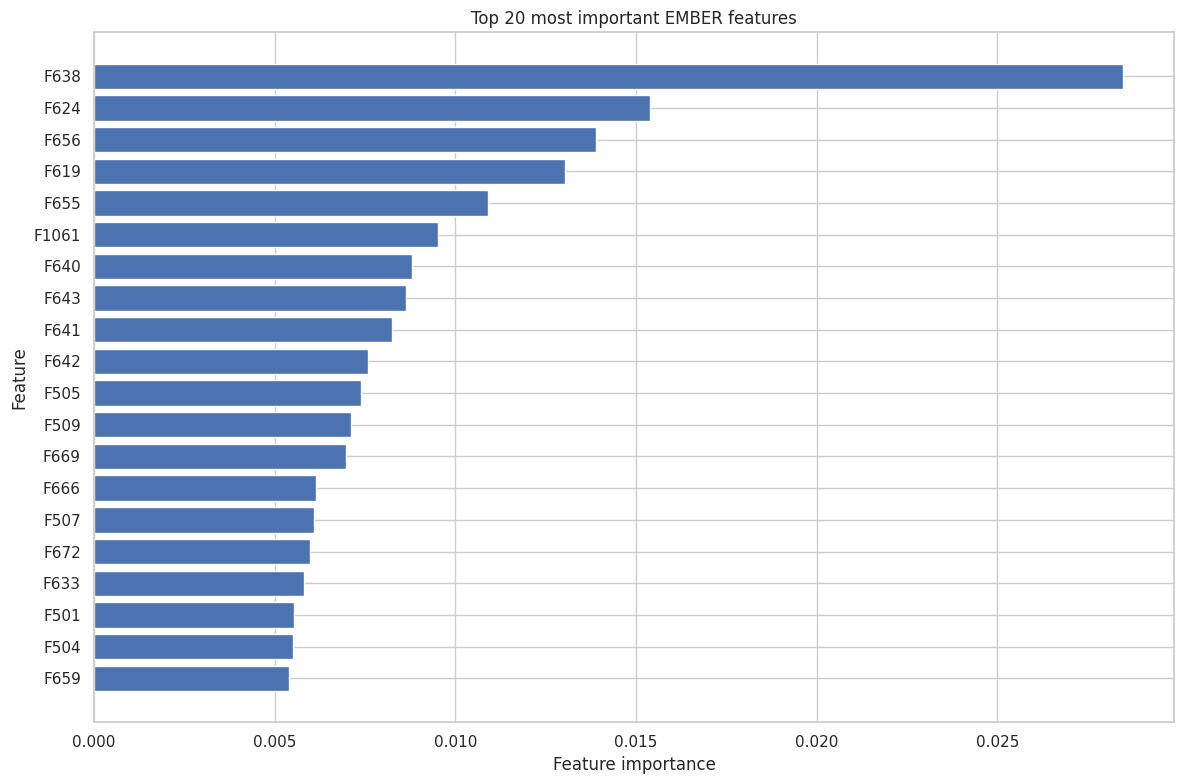

In [18]:
from sklearn.ensemble import ExtraTreesClassifier

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

importance_model = ExtraTreesClassifier(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_model.fit(X_train, y_train)

feature_importances = importance_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

def get_feature_group(feature):
    feature_index = int(feature[1:]) - 1

    for group_name, info in FEATURE_GROUPS.items():
        if info["start"] <= feature_index < info["end"]:
            return group_name

    return "Unknown"

importance_df["feature_group"] = (
    importance_df["feature"].apply(get_feature_group)
)

top_20_features = importance_df.head(20)

display(top_20_features)

plt.figure(figsize=(12, 8))

plt.barh(
    top_20_features["feature"][::-1],
    top_20_features["importance"][::-1]
)

plt.xlabel("Feature importance")

plt.ylabel("Feature")

plt.title("Top 20 most important EMBER features")

plt.tight_layout()

plt.show()

Elég-e 100 feature a közel 0.986-os ROC-AUC eléréséhez?



500 feature-rel mennyit veszítünk a teljes modellhez képest?



1000 feature fölött már csak minimális a teljesítménynövekedés?



Megéri-e mind a 2381 feature-t használni?

,n_features,feature_percentage,roc_auc,pr_auc,balanced_accuracy,f1
0,25,1.0500,0.9492,0.9489,0.8699,0.8728
1,50,2.1000,0.9770,0.9786,0.9145,0.9156
2,100,4.1999,0.9846,0.9858,0.9326,0.9328
3,250,10.4998,0.9857,0.9868,0.9326,0.9325
4,500,20.9996,0.9861,0.9873,0.9356,0.9354
5,1000,41.9992,0.9866,0.9878,0.9376,0.9372
6,1500,62.9987,0.9868,0.9881,0.9375,0.9371
7,2381,100.0000,0.9866,0.9879,0.9376,0.9372


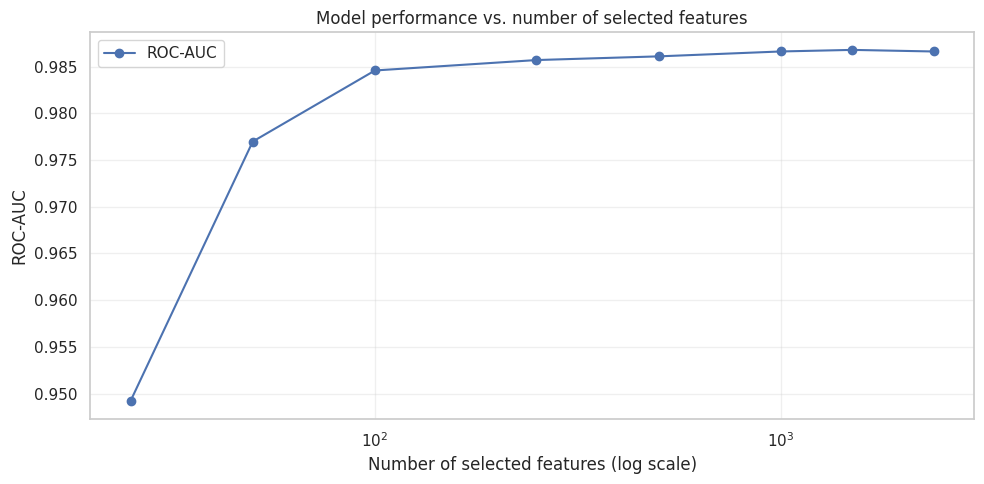

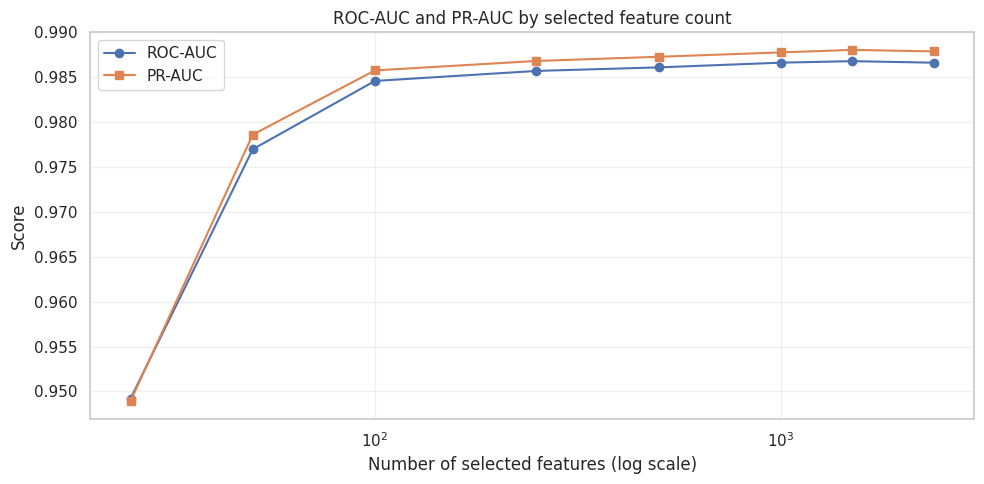

In [19]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score
)

feature_counts = [25, 50, 100, 250, 500, 1000, 1500, 2381]

ranked_features = importance_df["feature"].tolist()

selection_results = []

for n_features in feature_counts:

    selected_features = ranked_features[:n_features]

    # Oszlopindexek meghatározása
    selected_indices = [
        feature_names.index(feature)
        for feature in selected_features
    ]

    X_train_selected = X_train[:, selected_indices]
    X_val_selected = X_val[:, selected_indices]

    # Modell
    model = ExtraTreesClassifier(
        n_estimators=150,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_selected, y_train)

    # Predikciók
    y_pred = model.predict(X_val_selected)
    y_prob = model.predict_proba(X_val_selected)[:, 1]

    # Kiértékelés
    selection_results.append({
        "n_features": n_features,
        "feature_percentage": n_features / len(feature_names) * 100,
        "roc_auc": roc_auc_score(y_val, y_prob),
        "pr_auc": average_precision_score(y_val, y_prob),
        "balanced_accuracy": balanced_accuracy_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred)
    })

selection_results_df = pd.DataFrame(selection_results)

display(
    selection_results_df.round(4)
)

plt.figure(figsize=(10, 5))

plt.plot(
    selection_results_df["n_features"],
    selection_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xscale("log")

plt.xlabel("Number of selected features (log scale)")

plt.ylabel("ROC-AUC")

plt.title("Model performance vs. number of selected features")

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    selection_results_df["n_features"],
    selection_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.plot(
    selection_results_df["n_features"],
    selection_results_df["pr_auc"],
    marker="s",
    label="PR-AUC"
)

plt.xscale("log")

plt.xlabel("Number of selected features (log scale)")

plt.ylabel("Score")

plt.title("ROC-AUC and PR-AUC by selected feature count")

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()

Permutation Importance
Most egy másik módszerrel is ellenőrizzük, mely feature-ök fontosak. Az eddigi feature_importances_ a modell belső döntési folyamata alapján rangsorolt. A Permutation Importance ezzel szemben azt méri, mennyivel romlik a modell teljesítménye, ha egy adott feature értékeit véletlenszerűen összekeverjük.

Ez azért hasznos, mert így ellenőrizhetjük, hogy a korábban fontosnak talált jellemzők a validációs adatokon is valóban hasznosak-e.
3.1. Modell tanítása a 100 legfontosabb feature-rel

,feature,importance_mean,importance_std
0,F619,0.008172,0.000425
1,F624,0.007834,0.000394
2,F638,0.007360,0.000105
3,F1061,0.002245,0.000074
4,F643,0.001947,0.000150
5,F885,0.001942,0.000071
6,F641,0.001879,0.000071
7,F659,0.001791,0.000227
8,F931,0.001583,0.000129
9,F1175,0.001543,0.000126


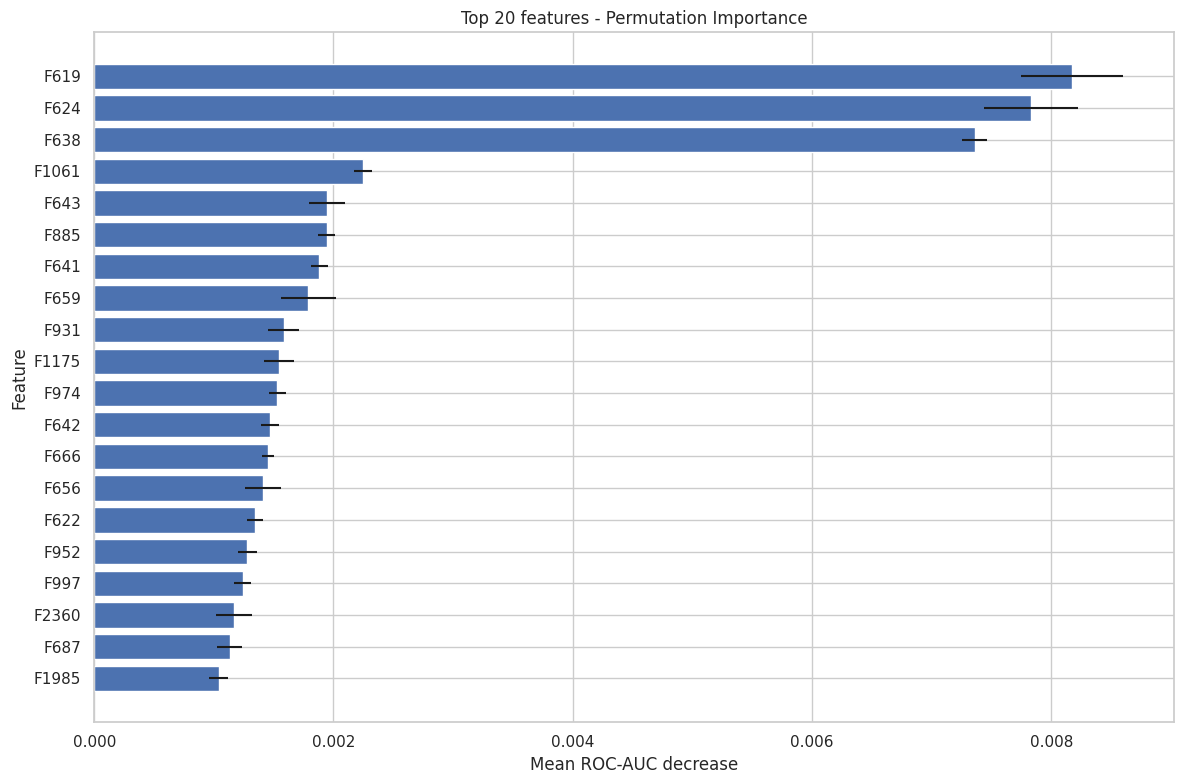

In [20]:
from sklearn.inspection import permutation_importance

selected_features = importance_df.head(100)["feature"].tolist()

selected_indices = [
    feature_names.index(feature)
    for feature in selected_features
]

X_train_selected = X_train[:, selected_indices]

X_val_selected = X_val[:, selected_indices]

permutation_model = ExtraTreesClassifier(
    n_estimators=150,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_model.fit(X_train_selected, y_train)

permutation_result = permutation_importance(
    permutation_model,
    X_val_selected,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "feature": selected_features,
    "importance_mean": permutation_result.importances_mean,
    "importance_std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="importance_mean",
    ascending=False
).reset_index(drop=True)

display(permutation_df.head(30).round(6))

top_permutation = permutation_df.head(20).sort_values(
    "importance_mean"
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_permutation["feature"],
    top_permutation["importance_mean"],
    xerr=top_permutation["importance_std"]
)

plt.xlabel("Mean ROC-AUC decrease")

plt.ylabel("Feature")

plt.title("Top 20 features - Permutation Importance")

plt.tight_layout()

plt.show()

100 feature elegendő lehet egy kompakt modellhez: a ROC-AUC 0.9846, ami nagyon közel van a teljes modell 0.9866-os eredményéhez.



250 feature jó kompromisszum: az eredmény 0.9857, miközben az eredeti jellemzők közel 90%-át elhagyjuk.



A legfontosabb feature-ök több csoportból származnak: a Header és General mellett az Imports is jelentős szerepet játszik.

döntési küszöb optimalizálása
Eddig az osztályozó alapértelmezett 0.5-ös döntési küszöbét használtuk. Most megvizsgáljuk, hogy más küszöbbel javítható-e az F1-score.

Először a 250 legfontosabb feature-rel tanítunk modellt:

In [21]:
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score
)

selected_features_250 = importance_df.head(250)["feature"].tolist()

selected_indices_250 = [
    feature_names.index(feature)
    for feature in selected_features_250
]

X_train_250 = X_train[:, selected_indices_250]

X_val_250 = X_val[:, selected_indices_250]

final_candidate_model = ExtraTreesClassifier(
    n_estimators=150,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

final_candidate_model.fit(X_train_250, y_train)

y_val_prob = final_candidate_model.predict_proba(X_val_250)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print(f"Optimal threshold: {best_threshold:.4f}")

print(f"Best validation F1: {f1_scores[best_index]:.4f}")

threshold_results = []

for threshold in [0.5, best_threshold]:

    y_pred_threshold = (
        y_val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "roc_auc": roc_auc_score(y_val, y_val_prob),
        "pr_auc": average_precision_score(y_val, y_val_prob),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, y_pred_threshold
        ),
        "f1": f1_score(y_val, y_pred_threshold)
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

Optimal threshold: 0.5311
Best validation F1: 0.9352


,threshold,roc_auc,pr_auc,balanced_accuracy,f1
0,0.5000,0.9857,0.9868,0.9326,0.9325
1,0.5311,0.9857,0.9868,0.9360,0.9352


az optimalizált döntési küszöb mindkét küszöbfüggő mérőszámot javította, miközben a modell rangsorolási képessége változatlan maradt.
1. A két küszöb összehasonlítása
Mérőszám	0.5 küszöb	0.5311 küszöb	Változás
ROC-AUC	0.9857	0.9857	0
PR-AUC	0.9868	0.9868	0
Balanced accuracy	0.9326	0.9360	+0.0034
F1	0.9325	0.9352	+0.0027

A végső modelljelölt:
- 250 kiválasztott feature;
- ExtraTreesClassifier;
- 150 döntési fa;
- 0.5311-es döntési küszöb.
5.1. Predikció a teszthalmazon
A korábban betanított final_candidate_model változót használjuk. Nem tanítjuk újra, mert a 0.5311-es küszöböt ehhez a modellhez optimalizáltuk.

,accuracy,precision,recall,f1,roc_auc,pr_auc,balanced_accuracy
0,0.9176,0.9117,0.9248,0.9182,0.9766,0.9786,0.9176



Classification report:
              precision    recall  f1-score   support

      Benign     0.9237    0.9104    0.9170      5000
     Malware     0.9117    0.9248    0.9182      5000

    accuracy                         0.9176     10000
   macro avg     0.9177    0.9176    0.9176     10000
weighted avg     0.9177    0.9176    0.9176     10000



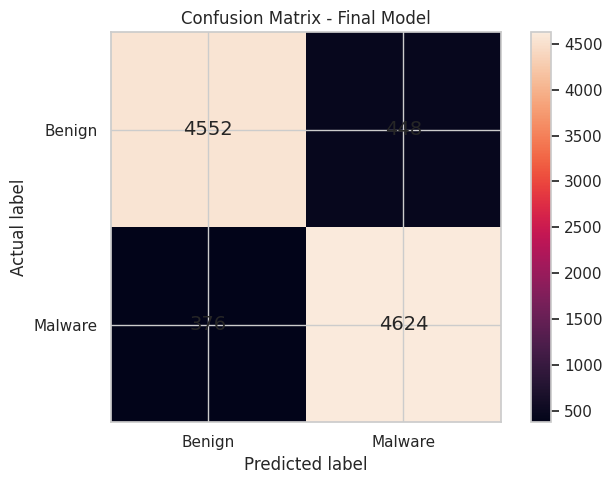

True Negatives: 4552
False Positives: 448
False Negatives: 376
True Positives: 4624


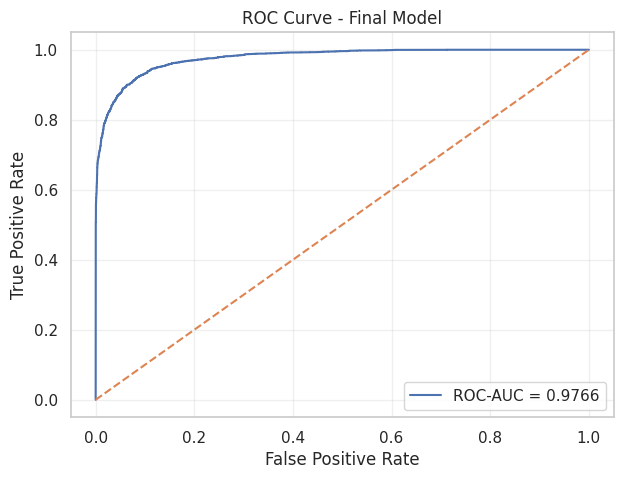

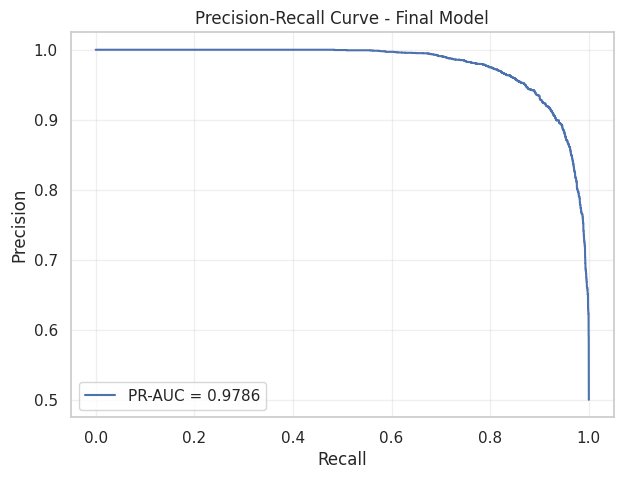

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

FINAL_THRESHOLD = best_threshold

X_test_250 = X_test[:, selected_indices_250]

y_test_prob = final_candidate_model.predict_proba(
    X_test_250
)[:, 1]

y_test_pred = (
    y_test_prob >= FINAL_THRESHOLD
).astype(int)

test_results = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1": f1_score(y_test, y_test_pred),
    "roc_auc": roc_auc_score(y_test, y_test_prob),
    "pr_auc": average_precision_score(y_test, y_test_prob),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, y_test_pred
    )
}

test_results_df = pd.DataFrame(
    [test_results]
)

display(test_results_df.round(4))

print("\nClassification report:")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Benign", "Malware"],
        digits=4
    )
)

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Confusion Matrix - Final Model")

plt.xlabel("Predicted label")

plt.ylabel("Actual label")

plt.xticks([0, 1], ["Benign", "Malware"])

plt.yticks([0, 1], ["Benign", "Malware"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()

plt.show()

print("True Negatives:", cm[0, 0])

print("False Positives:", cm[0, 1])

print("False Negatives:", cm[1, 0])

print("True Positives:", cm[1, 1])

from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_test, y_test_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC-AUC = {test_results['roc_auc']:.4f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Final Model")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

precision_values, recall_values, _ = precision_recall_curve(
    y_test, y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"PR-AUC = {test_results['pr_auc']:.4f}"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve - Final Model")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

A végső ExtraTrees modell 250 kiválasztott feature felhasználásával 0,9766 ROC-AUC és 91,76%-os accuracy értéket ért el az elkülönített teszthalmazon. A modellt a validációs adatokon optimalizált 0,5311-es döntési küszöbbel értékeltük.

A confusion matrix alapján a modell 4624 malware és 4552 benign mintát osztályozott helyesen. A hibás besorolások között 376 False Negative és 448 False Positive szerepelt. A malware osztály recall értéke 92,48%, ami azt jelenti, hogy a tesztmintában szereplő malware fájlok 7,52%-át a modell nem ismerte fel.

A validációs és teszteredmények közötti különbség arra utal, hogy a modell teljesítménye az ismeretlen adatokon valamelyest csökkent. Ennek ellenére a 250 feature-rel elért eredmény azt mutatja, hogy a teljes 2381 jellemzőből álló adatkészlet jelentős része elhagyható a prediktív teljesítmény viszonylag kis mértékű csökkenése mellett.

Error distribution:


,count
error_type,
Correct,9176
False Positive,448
False Negative,376


Top 10 False Negatives:


,sample_index,actual_label,predicted_label,malware_probability,error_type
9912,9912,1,0,0.031115,False Negative
7830,7830,1,0,0.037780,False Negative
4583,4583,1,0,0.070008,False Negative
6892,6892,1,0,0.071116,False Negative
6524,6524,1,0,0.073341,False Negative
1058,1058,1,0,0.074449,False Negative
436,436,1,0,0.077784,False Negative
1458,1458,1,0,0.081118,False Negative
8419,8419,1,0,0.086671,False Negative
5357,5357,1,0,0.106673,False Negative


Top 10 False Positives:


,sample_index,actual_label,predicted_label,malware_probability,error_type
5695,5695,0,1,0.941118,False Positive
8127,8127,0,1,0.928896,False Positive
8723,8723,0,1,0.903340,False Positive
2465,2465,0,1,0.900562,False Positive
3152,3152,0,1,0.893343,False Positive
6874,6874,0,1,0.891676,False Positive
695,695,0,1,0.887233,False Positive
451,451,0,1,0.885005,False Positive
6976,6976,0,1,0.884455,False Positive
8795,8795,0,1,0.874453,False Positive


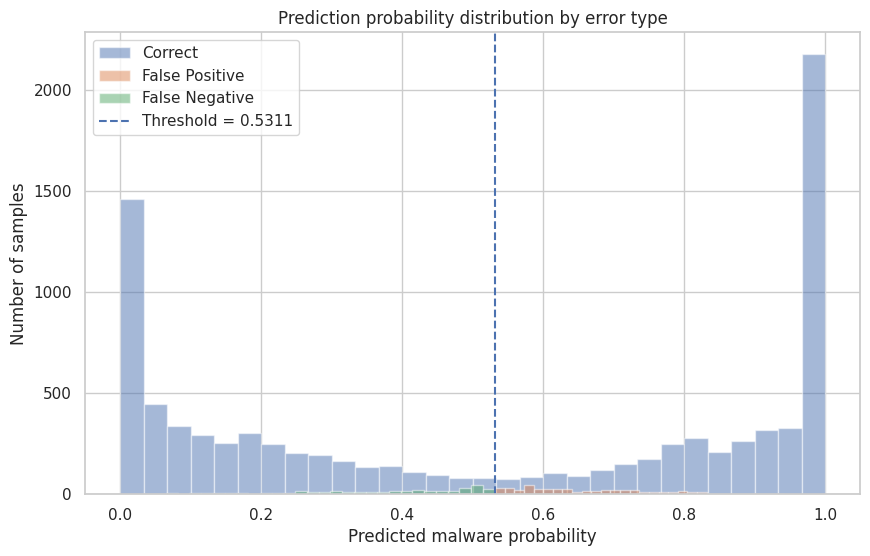

In [23]:
error_analysis_df = pd.DataFrame({
    "sample_index": np.arange(len(y_test)),
    "actual_label": y_test,
    "predicted_label": y_test_pred,
    "malware_probability": y_test_prob
})

error_analysis_df["error_type"] = "Correct"

error_analysis_df.loc[
    (y_test == 0) & (y_test_pred == 1),
    "error_type"
] = "False Positive"

error_analysis_df.loc[
    (y_test == 1) & (y_test_pred == 0),
    "error_type"
] = "False Negative"

print("Error distribution:")

display(
    error_analysis_df["error_type"]
    .value_counts()
    .to_frame("count")
)

false_negatives = (
    error_analysis_df[
        error_analysis_df["error_type"] == "False Negative"
    ]
    .sort_values("malware_probability")
)

false_positives = (
    error_analysis_df[
        error_analysis_df["error_type"] == "False Positive"
    ]
    .sort_values("malware_probability", ascending=False)
)

print("Top 10 False Negatives:")

display(false_negatives.head(10))

print("Top 10 False Positives:")

display(false_positives.head(10))

plt.figure(figsize=(10, 6))

for category in ["Correct", "False Positive", "False Negative"]:
    values = error_analysis_df.loc[
        error_analysis_df["error_type"] == category,
        "malware_probability"
    ]

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=category
    )

plt.axvline(
    FINAL_THRESHOLD,
    linestyle="--",
    label=f"Threshold = {FINAL_THRESHOLD:.4f}"
)

plt.xlabel("Predicted malware probability")

plt.ylabel("Number of samples")

plt.title("Prediction probability distribution by error type")

plt.legend()

plt.show()

A validációs halmazon optimalizált 0,5311-es küszöb módosítása valószínűleg nem oldaná meg ezeket a szélsőséges hibákat.
- A küszöb emelése csökkentheti a False Positive esetek számát, de várhatóan növeli a False Negative esetekét.
- A küszöb csökkentése csökkentheti a False Negative eseteket, de várhatóan növeli a False Positive eseteket.
A 3–10%-os és 87–94%-os becslések alapján azonban ezek a minták nem pusztán a küszöb rossz megválasztása miatt kerültek rossz osztályba.

A hibás minták jellemzőinek vizsgálata
Érdemes megnézni, hogy a hibás minták miben különböznek a helyesen osztályozott mintáktól. Például mely feature-csoportokban térnek el leginkább.

In [24]:
# A téves és helyes predikciók feature-csoport szintű összehasonlítása.
error_mask = error_analysis_df["error_type"] != "Correct"
correct_mask = error_analysis_df["error_type"] == "Correct"

error_indices = np.flatnonzero(error_mask.to_numpy())
correct_indices = np.flatnonzero(correct_mask.to_numpy())

error_group_stats = []

for group_name, group_info in FEATURE_GROUPS.items():
    start = group_info["start"]
    end = group_info["end"]

    error_mean = X_test[error_indices, start:end].mean()
    correct_mean = X_test[correct_indices, start:end].mean()

    error_group_stats.append({
        "feature_group": group_name,
        "error_mean": error_mean,
        "correct_mean": correct_mean,
        "absolute_difference": abs(error_mean - correct_mean)
    })

error_group_df = pd.DataFrame(error_group_stats)

display(
    error_group_df.sort_values(
        "absolute_difference",
        ascending=False
    )
)


,feature_group,error_mean,correct_mean,absolute_difference
4,Header,2.037386e+07,2.199899e+07,1.625130e+06
8,Data directories,4.157997e+05,3.549313e+05,6.086838e+04
3,General,3.129088e+05,3.097568e+05,3.152000e+03
5,Section,3.230538e+03,2.608334e+03,6.222041e+02
2,Strings,7.658398e+02,6.126320e+02,1.532078e+02
6,Imports,-4.957714e-03,-2.556516e-03,2.401198e-03
7,Exports,1.678171e-03,2.996949e-04,1.378476e-03
0,Byte histogram,3.906250e-03,3.906250e-03,0.000000e+00
1,Byte entropy,3.906250e-03,3.906250e-03,0.000000e+00


### Következtetések a hibaanalízis alapján

A helyesen és hibásan osztályozott minták feature-csoportonkénti összehasonlítása alapján több jellemzőcsoport esetében is megfigyelhető eltérés a két csoport átlagos értékei között.

A legnagyobb abszolút különbség a Header jellemzőcsoportban jelentkezik, amelyet a Data directories követ. A General, Section és Strings csoportok esetében kisebb eltérések figyelhetők meg, míg az Imports és Exports csoportoknál az átlagok közötti különbség lényegesen kisebb. A Byte histogram és Byte entropy csoportok átlagai megegyeznek a két mintacsoportban.

Az eredmények arra utalnak, hogy bizonyos PE-fájlokra jellemző tulajdonságcsoportok eloszlása eltérhet a modell által helyesen és hibásan osztályozott minták között. Ez további vizsgálatot indokolhat, különösen a Header és Data directories jellemzőcsoportok esetében.

Fontos azonban, hogy az átlagértékek összehasonlítása önmagában nem bizonyít ok-okozati kapcsolatot, és nem mutatja meg közvetlenül az egyes feature-csoportok modellre gyakorolt hatását. A különböző nagyságrendű értékek miatt az abszolút különbségeket is körültekintően kell értelmezni. A pontosabb következtetésekhez a szórások, eloszlások és relatív különbségek vizsgálata is szükséges.

In [25]:
import numpy as np
import pandas as pd

# A hibás és helyes predikciók maszkjai
error_mask = error_analysis_df["error_type"] != "Correct"
correct_mask = error_analysis_df["error_type"] == "Correct"

# A vizsgált feature-csoportok
groups_to_check = ["Header", "Data directories"]

results = []

for group_name in groups_to_check:

    info = FEATURE_GROUPS[group_name]
    start = info["start"]
    end = info["end"]

    # A csoport feature-ei
    X_group = X_test[:, start:end]

    for local_idx in range(end - start):

        feature_idx = start + local_idx
        feature_name = feature_names[feature_idx]

        error_values = X_group[error_mask.to_numpy(), local_idx]
        correct_values = X_group[correct_mask.to_numpy(), local_idx]

        # Átlagok és mediánok
        error_mean = np.mean(error_values)
        correct_mean = np.mean(correct_values)

        error_median = np.median(error_values)
        correct_median = np.median(correct_values)

        # Szórások
        error_std = np.std(error_values)
        correct_std = np.std(correct_values)

        # Standardizált különbség (Cohen-féle d)
        pooled_std = np.sqrt(
            (error_std**2 + correct_std**2) / 2
        )

        cohens_d = (
            (error_mean - correct_mean) / pooled_std
            if pooled_std > 1e-12
            else 0
        )

        results.append({
            "feature": feature_name,
            "feature_group": group_name,
            "error_mean": error_mean,
            "correct_mean": correct_mean,
            "error_median": error_median,
            "correct_median": correct_median,
            "error_std": error_std,
            "correct_std": correct_std,
            "cohens_d": cohens_d,
            "abs_cohens_d": abs(cohens_d)
        })

feature_comparison_df = pd.DataFrame(results)

# Legnagyobb standardizált eltérések
display(
    feature_comparison_df
    .sort_values("abs_cohens_d", ascending=False)
    .head(30)
    .round(4)
)

,feature,feature_group,error_mean,correct_mean,error_median,correct_median,error_std,correct_std,cohens_d,abs_cohens_d
39,F666,Header,-6.670000e-02,-1.781000e-01,0.000000e+00,0.000000e+00,2.496000e-01,3.826000e-01,0.3447,0.3447
13,F640,Header,-9.806000e-01,-9.104000e-01,-1.000000e+00,-1.000000e+00,1.380000e-01,2.856000e-01,-0.3129,0.3129
29,F656,Header,-9.539000e-01,-8.765000e-01,-1.000000e+00,-1.000000e+00,2.097000e-01,3.293000e-01,-0.2802,0.2802
0,F627,Header,1.262630e+09,1.362659e+09,1.323782e+09,1.443514e+09,3.051286e+08,4.324532e+08,-0.2673,0.2673
53,F680,Header,7.865300e+00,1.059830e+01,7.000000e+00,7.000000e+00,6.775900e+00,1.304800e+01,-0.2629,0.2629
28,F655,Header,4.250000e-02,1.108000e-01,0.000000e+00,0.000000e+00,2.017000e-01,3.278000e-01,-0.2512,0.2512
31,F658,Header,3.600000e-03,2.720000e-02,0.000000e+00,0.000000e+00,6.020000e-02,1.628000e-01,-0.1923,0.1923
86,F2376,Data directories,6.758204e+02,4.947752e+02,4.260000e+02,2.360000e+02,8.869153e+02,1.054629e+03,0.1858,0.1858
80,F2370,Data directories,5.582500e+00,3.470900e+00,0.000000e+00,0.000000e+00,1.398410e+01,9.691400e+00,0.1755,0.1755
6,F633,Header,9.818000e-01,9.509000e-01,1.000000e+00,1.000000e+00,1.337000e-01,2.162000e-01,0.1722,0.1722


További vizsgálat:

In [26]:
# A predikciók és valódi címkék alapján
fp_mask = (y_test == 0) & (y_test_pred == 1)
fn_mask = (y_test == 1) & (y_test_pred == 0)
correct_mask = (y_test == y_test_pred)

print("False Positive:", fp_mask.sum())
print("False Negative:", fn_mask.sum())
print("Correct:", correct_mask.sum())

False Positive: 448
False Negative: 376
Correct: 9176


- 824 hibásan osztályozott mintát vizsgáltál (448 FP + 376 FN).
- 9176 helyesen osztályozott mintát hasonlítottál össze velük.
Ez megfelelő első lépés, de van egy fontos lehetőség a további elemzésre: érdemes lenne külön megvizsgálni a False Positive és False Negative eseteket.

Ugyanis a két hibatípus eltérő problémát jelent:
- False Positive: a modell ártalmatlan fájlt kártékonyként azonosít.
- False Negative: a modell kártékony fájlt ártalmatlanként azonosít.
Elképzelhető, hogy más feature-ök jellemzik az egyik és mások a másik hibacsoportot.

In [27]:
# A hibák pontos eloszlása
print(error_analysis_df["error_type"].value_counts())

# Az egyes csoportok aránya
print(
    error_analysis_df["error_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

error_type
Correct           9176
False Positive     448
False Negative     376
Name: count, dtype: int64
error_type
Correct           91.76
False Positive     4.48
False Negative     3.76
Name: proportion, dtype: float64


In [28]:
groups_to_check = ["Header", "Data directories"]

results = []

for group_name in groups_to_check:
    info = FEATURE_GROUPS[group_name]
    start, end = info["start"], info["end"]

    for feature_idx in range(start, end):
        feature_name = feature_names[feature_idx]
        values = X_test[:, feature_idx]

        for error_type in ["Correct", "False Positive", "False Negative"]:
            mask = (
                error_analysis_df["error_type"]
                .to_numpy() == error_type
            )

            group_values = values[mask]

            results.append({
                "feature": feature_name,
                "feature_group": group_name,
                "error_type": error_type,
                "mean": np.mean(group_values),
                "median": np.median(group_values),
                "std": np.std(group_values)
            })

error_type_comparison = pd.DataFrame(results)

display(
    error_type_comparison
    .sort_values(["feature_group", "feature"])
    .round(4)
)

,feature,feature_group,error_type,mean,median,std
186,F2352,Data directories,Correct,4.713751e+05,0.0,4.483443e+07
187,F2352,Data directories,False Positive,6.651719e+02,0.0,7.020908e+03
188,F2352,Data directories,False Negative,1.142500e+07,0.0,2.212010e+08
189,F2353,Data directories,Correct,1.621661e+05,0.0,1.564668e+06
190,F2353,Data directories,False Positive,2.450649e+05,0.0,2.110298e+06
...,...,...,...,...,...,...
181,F687,Header,False Positive,2.251428e+03,1024.0,1.530901e+03
182,F687,Header,False Negative,1.812426e+03,1024.0,1.360633e+03
183,F688,Header,Correct,8.041988e+03,4096.0,2.477121e+05
184,F688,Header,False Positive,4.096000e+03,4096.0,0.000000e+00


Feature	Correct átlag	FP átlag	FN átlag
F2352	471 375	665	11 425 000
F2353	162 166	245 065	–
F688	8042	4096	4096

F2352 – Data directories
- A False Negative csoport átlaga rendkívül magas.
- A medián mindhárom csoportban 0.
- Ez arra utal, hogy a minták jelentős részében az érték nulla, miközben néhány nagyon nagy érték erősen megemeli az átlagot.
- A False Negative mintákban különösen szélsőséges értékek lehetnek.
F688 – Header
- A False Positive és False Negative csoport átlaga és mediánja azonos.
- A Correct csoport átlaga viszont magasabb.
- Ez önmagában még nem jelenti azt, hogy az F688 alkalmas a hibás minták elkülönítésére.

Kiugró értékek vizsgálata:

In [29]:
results = []

for feature_name in ["F2352", "F2353", "F688"]:
    feature_idx = feature_names.index(feature_name)
    values = X_test[:, feature_idx]

    for error_type in ["Correct", "False Positive", "False Negative"]:
        mask = (
            error_analysis_df["error_type"].to_numpy()
            == error_type
        )

        group_values = values[mask]

        results.append({
            "feature": feature_name,
            "error_type": error_type,
            "count": len(group_values),
            "zero_ratio": np.mean(group_values == 0),
            "p95": np.percentile(group_values, 95),
            "p99": np.percentile(group_values, 99),
            "p999": np.percentile(group_values, 99.9),
            "max": np.max(group_values)
        })

outlier_analysis = pd.DataFrame(results)

display(outlier_analysis.round(4))

,feature,error_type,count,zero_ratio,p95,p99,p999,max
0,F2352,Correct,9176,0.8433,477.000000,2.951075e+04,4.032242e+05,4.294963e+09
1,F2352,False Positive,448,0.8817,149.550003,1.362258e+04,9.506673e+04,1.264220e+05
2,F2352,False Negative,376,0.7367,3404.500000,9.721825e+04,2.684435e+09,4.294963e+09
3,F2353,Correct,9176,0.8466,393220.000000,3.127244e+06,2.007509e+07,7.158579e+07
4,F2353,False Positive,448,0.8817,488276.781250,5.607759e+06,2.787662e+07,4.052716e+07
5,F2353,False Negative,376,0.7420,686648.000000,1.657072e+06,7.270400e+06,8.388608e+06
6,F688,Correct,9176,0.0096,4096.000000,8.192000e+03,5.785600e+04,1.677722e+07
7,F688,False Positive,448,0.0000,4096.000000,4.096000e+03,4.096000e+03,4.096000e+03
8,F688,False Negative,376,0.0000,4096.000000,4.096000e+03,4.096000e+03,4.096000e+03


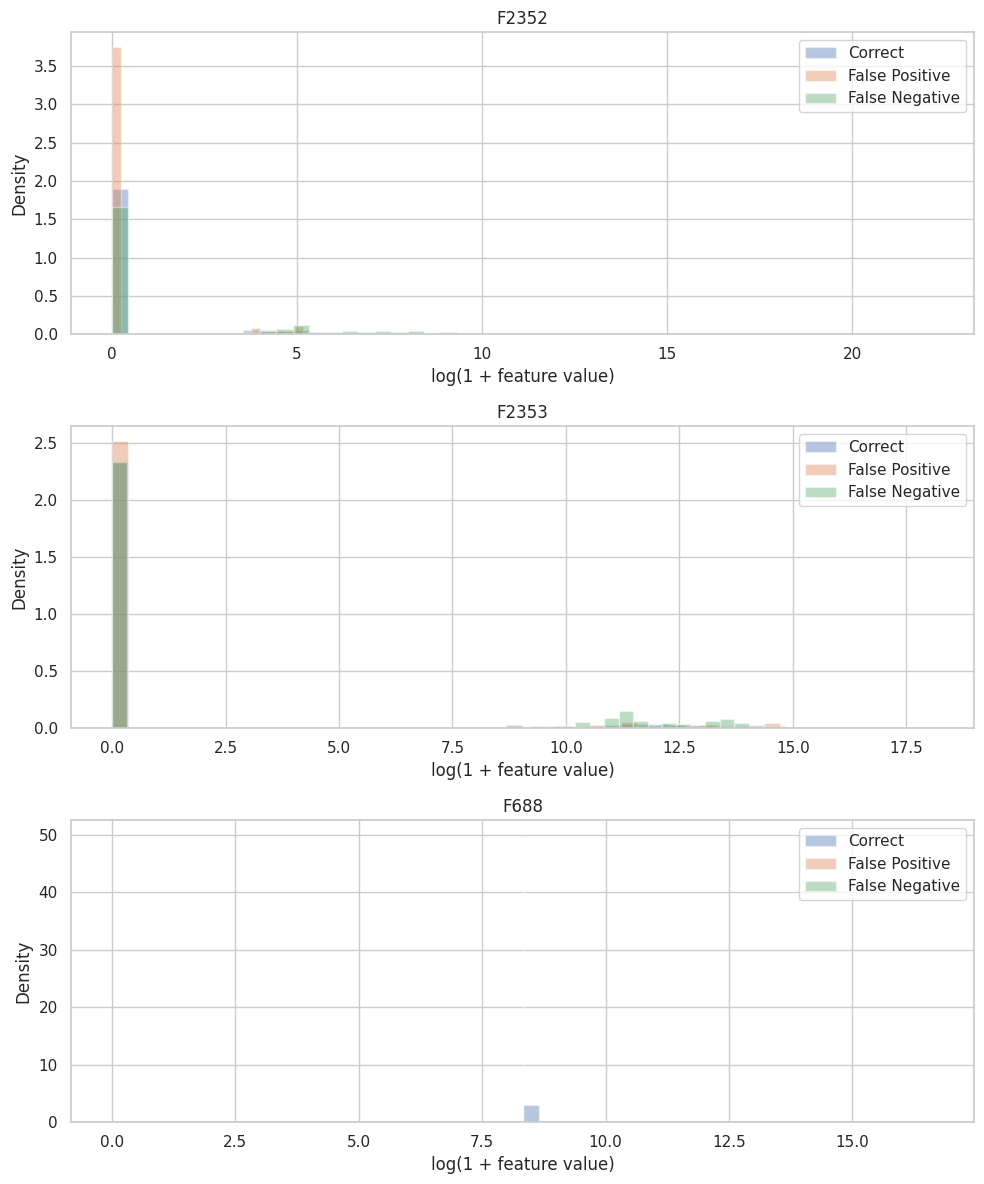

In [30]:
import matplotlib.pyplot as plt

features_to_plot = ["F2352", "F2353", "F688"]
error_types = ["Correct", "False Positive", "False Negative"]

fig, axes = plt.subplots(
    len(features_to_plot),
    1,
    figsize=(10, 12)
)

for ax, feature_name in zip(axes, features_to_plot):

    feature_idx = feature_names.index(feature_name)

    for error_type in error_types:
        mask = (
            error_analysis_df["error_type"].to_numpy()
            == error_type
        )

        values = X_test[mask, feature_idx]

        # A nulla és negatív értékek miatt log1p-transzformáció
        transformed = np.log1p(np.maximum(values, 0))

        ax.hist(
            transformed,
            bins=50,
            alpha=0.4,
            density=True,
            label=error_type
        )

    ax.set_title(feature_name)
    ax.set_xlabel("log(1 + feature value)")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

A Data directories feature-csoport vizsgálata során az F2352 és F2353 jellemzők esetében jelentős számú nulla érték figyelhető meg mindhárom osztályozási kategóriában. A nem nulla értékek eloszlása azonban eltéréseket mutat. Különösen az F2352 esetében figyelhető meg, hogy a False Negative minták között nagyobb értékek is előfordulnak, ami összhangban áll a csoport kiugróan magas átlagával. Az eredmények arra utalnak, hogy bizonyos jellemzők eloszlása eltérhet a helyesen és hibásan osztályozott minták között. Ezek a különbségek további vizsgálatot indokolnak.

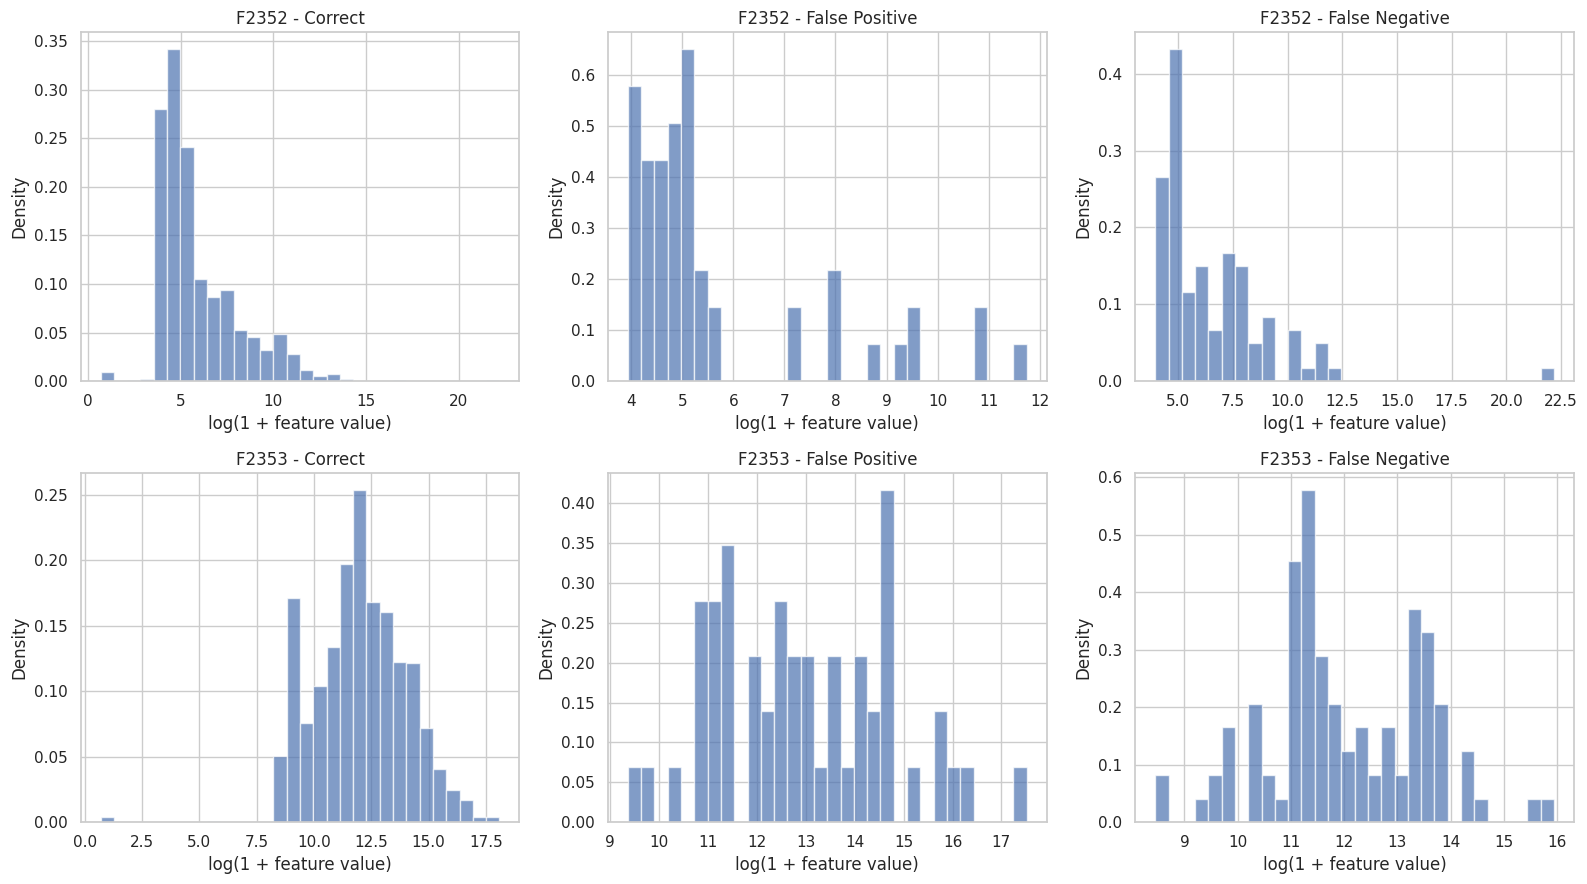

In [33]:
import matplotlib.pyplot as plt
import numpy as np

features_to_plot = ["F2352", "F2353"]
error_types = ["Correct", "False Positive", "False Negative"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for row, feature_name in enumerate(features_to_plot):

    feature_idx = feature_names.index(feature_name)

    for col, error_type in enumerate(error_types):

        mask = (
            error_analysis_df["error_type"].to_numpy()
            == error_type
        )

        values = X_test[mask, feature_idx]

        # Csak a nem nulla értékek
        nonzero_values = values[values > 0]

        ax = axes[row, col]

        if len(nonzero_values) > 0:
            ax.hist(
                np.log1p(nonzero_values),
                bins=30,
                density=True,
                alpha=0.7
            )

        ax.set_title(f"{feature_name} - {error_type}")
        ax.set_xlabel("log(1 + feature value)")
        ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

### A Data directories jellemzők vizsgálata a hibás osztályozások tükrében

Az F2352 és F2353 jellemzők esetében mindhárom osztályozási kategóriában magas a nulla értékek aránya. A nulla értékek aránya ugyanakkor eltér a csoportok között: a False Positive minták esetében mindkét jellemzőnél meghaladja a 88%-ot, míg a False Negative minták esetében körülbelül 74%.

Ez arra utal, hogy a hibásan osztályozott minták két kategóriája eltérő eloszlási tulajdonságokkal rendelkezhet. A nem nulla értékek hisztogramjai szintén különbségeket mutatnak, ugyanakkor az eloszlások között jelentős átfedés figyelhető meg.

Az eredmények alapján az F2352 és F2353 jellemzők további vizsgálata indokolt, de önmagukban nem tekinthetők a téves osztályozások egyértelmű magyarázatának.

In [32]:
zero_results = []

for feature_name in ["F2352", "F2353"]:
    feature_idx = feature_names.index(feature_name)

    values = X_test[:, feature_idx]

    for error_type in ["Correct", "False Positive", "False Negative"]:

        mask = (
            error_analysis_df["error_type"].to_numpy()
            == error_type
        )

        group_values = values[mask]

        zero_results.append({
            "feature": feature_name,
            "error_type": error_type,
            "sample_count": len(group_values),
            "zero_count": np.sum(group_values == 0),
            "zero_percentage": np.mean(group_values == 0) * 100
        })

display(pd.DataFrame(zero_results).round(2))

,feature,error_type,sample_count,zero_count,zero_percentage
0,F2352,Correct,9176,7738,84.33
1,F2352,False Positive,448,395,88.17
2,F2352,False Negative,376,277,73.67
3,F2353,Correct,9176,7768,84.66
4,F2353,False Positive,448,395,88.17
5,F2353,False Negative,376,279,74.20


In [34]:
import joblib

# A megfelelő, memóriában lévő változónevek használata
model_artifact = {
    "model": final_candidate_model,
    "feature_names": selected_features_250,
    "threshold": best_threshold
}

joblib.dump(
    model_artifact,
    "ember_malware_detector.pkl"
)
print("A modell sikeresen elmentve 'ember_malware_detector.pkl' néven!")

A modell sikeresen elmentve 'ember_malware_detector.pkl' néven!


In [36]:
import os
from google.colab import files

file_name = "ember_malware_detector.pkl"

# 1. Ellenőrizzük, hogy a fájl létezik-e a Colab környezetben
if os.path.exists(file_name):
    file_size_mb = os.path.getsize(file_name) / (1024 * 1024)
    print(f"[SIKER] A fájl létezik a Colab tárhelyén!")
    print(f"Fájl mérete: {file_size_mb:.2f} MB")
    print("\nMegpróbálom elindítani a letöltést...")

    # 2. Letöltés kényszerítése a böngészőn keresztül
    try:
        files.download(file_name)
    except Exception as e:
        print(f"Hiba történt a letöltés indításakor: {e}")
        print("Ha nem indul el a letöltés, ellenőrizze a böngészője felugró ablak (pop-up) blokkolóját!")
else:
    print(f"[HIBA] A(z) '{file_name}' fájl nem található a Colab tárhelyén. Kérjük, futtassa újra az elmentő cellát!")

[SIKER] A fájl létezik a Colab tárhelyén!
Fájl mérete: 82.78 MB

Megpróbálom elindítani a letöltést...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Alternatív megoldás: Manuális letöltés a menüből

Ha a fenti kód futtatása után sem indul el a letöltés, a fájlt manuálisan is lementheti az alábbi lépésekkel:

1. Kattintson a Google Colab **bal oldali sávjában** található **mappa ikonra** (📁 *Files* / *Fájlok*).
2. Keresse meg a listában az `ember_malware_detector.pkl` nevű fájlt.
3. Vigye fölé az egeret, kattintson a neve mellett megjelenő **három pontra** (további lehetőségek).
4. Válassza a **Download** (*Letöltés*) lehetőséget.

## Záró módszertani megjegyzések és korlátok

- A teszthalmaz eredményei csak a vizsgált mintára és mintavételi eljárásra vonatkoznak. Ha a tesztmintát kiegyensúlyozottan állítjuk elő, a precision és a PR-AUC nem feltétlenül tükrözi a valós telepítési osztályarányokat.
- A feature importance és a permutation importance rangsorok; önmagukban nem bizonyítanak oksági kapcsolatot.
- A feature-csoportok nyers átlagai eltérő skálákon lehetnek, ezért közvetlenül nem hasonlíthatók össze normalizálás vagy standardizálás nélkül.
- A minták közötti duplikációk, illetve az azonos malware-családhoz tartozó fájlok train/test közötti átfedése további vizsgálatot igényelhet.
- A végső tesztértékelés után a teszthalmaz alapján nem szabad újrahangolni a modellt vagy a döntési küszöböt.
